# RQ1: Predicting meal-level glycemic response 

**Goal.** Predict the 0 to 120 min positive iAUC of each eligible meal from nested feature sets, and compare three model families under participant-grouped cross-validation.

| Set | Features | Target |
|---|---|---|
| **M1** | food macros (carbs, protein, fat, fiber) | raw |
| **M2** | M1 + pre-meal glucose (mean, slope, last, SD), heart rate, physical activity, meal context | raw |
| **M3** | M2 + blood biomarkers / demographics (age, BMI, HbA1c, fasting glucose, insulin) | raw |
| **M4** | M3 + gut-health scores (gut-matched participants only) | raw |

**Models:** Ridge, XGBoost. **Evaluation:** 5-fold participant-grouped outer CV with nested grouped CV for hyperparameters; pooled out-of-fold RMSE, MAE, R², mean participant MAE and more.

**Targets.** Ridge and XGBoost are each run twice: on **`y_raw`** (iAUC in mg/dL·min) 

In [1]:
import os
import re
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from IPython.display import display

from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import GammaRegressor, Ridge
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, median_absolute_error, r2_score,
)
from sklearn.model_selection import GridSearchCV, GroupKFold, cross_val_predict
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from scipy.stats import pearsonr
import statsmodels.formula.api as smf
from scipy.stats import chi2, norm


import xgboost as xgb

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

# ---------------------------------------------------------------- settings
SEED = 32
DATA_DIR = Path(os.environ.get(
    "CGMACROS_DIR",
    "/Users/pavithraa/Desktop/BME_Data_Science/Project/Glucose-macros-data/"
    "cgmacros-code/cgmacros-data/CGMacros",
))
OUT_DIR = Path("results_log_target")
OUT_DIR.mkdir(exist_ok=True)

EXCLUDED_SUBJECTS = {18: "Repeated 900/901-minute timestamp jumps; timing unresolved"}

# Meal-window rules (identical to code_explore.ipynb)
BASELINE_MINUTES = 15
RESPONSE_MINUTES = 120
PREVIOUS_FOOD_MINUTES = 180
MAX_MISSING_RUN = 5
MIN_BASELINE_VALID = 12      # of 15 baseline minutes
MIN_RESPONSE_VALID = 97      # of 121 response minutes (80%)

# Pre-meal feature window
PREMEAL_MINUTES = 30
PREMEAL_MIN_VALID = 24       # 80% of the 30 minutes

# Features with lower coverage than this are dropped from premeal/activity groups
MIN_FEATURE_COVERAGE = 0.40

OUTER_FOLDS = 5
INNER_FOLDS = 5

## 1. Load and clean participant-level tables
Same checks as the original notebook: IDs must be unique integers, documented erroneous lab values (LDL = 800, VLDL = 400) are set to missing, and each participant is flagged for whether a gut profile exists.

In [2]:
def load_metadata(filename):
    """Load a table and validate IDs so later joins cannot duplicate meals."""
    path = DATA_DIR / filename
    table = pd.read_csv(path, encoding="utf-8-sig")
    table.columns = table.columns.str.strip()
    ids = pd.to_numeric(table["subject"], errors="coerce")
    table["subject"] = ids.astype(int)
    return table


bio_raw = load_metadata("bio.csv")
gut_raw = load_metadata("gut_health_test.csv")
bio, gut = bio_raw.copy(), gut_raw.copy()

# Documented erroneous values -> missing (modeling copy only)
quality_flags = []
for column, error_value in [("LDL (Cal)", 800), ("VLDL (Cal)", 400)]:
    if column not in bio.columns:
        continue
    mask = bio[column].eq(error_value)
    for subject in bio.loc[mask, "subject"]:
        quality_flags.append({"subject": int(subject), "variable": column,
                              "original_value": error_value, "action": "Set to missing"})
    bio.loc[mask, column] = np.nan

gut_columns = gut.columns.drop("subject").tolist()
gut_subjects = set(gut.loc[gut[gut_columns].notna().any(axis=1), "subject"])
bio["has_gut_data"] = bio["subject"].isin(gut_subjects)

print("bio shape:", bio.shape, "| gut shape:", gut.shape)
print("Participants with gut data:", int(bio["has_gut_data"].sum()),
      "| without:", int((~bio["has_gut_data"]).sum()))
print("\nBlood/demographic columns:", [c for c in bio.columns if c != "subject"])
print("\nQuality flags:")
print(pd.DataFrame(quality_flags).to_string(index=False) if quality_flags else "none")

bio shape: (45, 25) | gut shape: (47, 23)
Participants with gut data: 42 | without: 3

Blood/demographic columns: ['Age', 'Gender', 'BMI', 'Body weight', 'Height', 'Self-identify', 'A1c PDL (Lab)', 'Fasting GLU - PDL (Lab)', 'Insulin', 'Triglycerides', 'Cholesterol', 'HDL', 'Non HDL', 'LDL (Cal)', 'VLDL (Cal)', 'Cho/HDL Ratio', 'Collection time PDL (Lab)', '#1 Contour Fingerstick GLU', 'Time (t)', '#2 Contour Fingerstick GLU', 'Time (t).1', '#3 Contour Fingerstick GLU', 'Time (t).2', 'has_gut_data']

Quality flags:
 subject   variable  original_value         action
      12  LDL (Cal)             800 Set to missing
      12 VLDL (Cal)             400 Set to missing


## 2. Load each participant files
Each file is read **once**, headers are harmonised, and the cleaned frame is cached in `frames[subject]`.

Activity columns differ between files (some have `METs`/`Steps`, others `Calories (Activity)`/`Intensity`), so headers are normalised to `METs`, `Steps`, `Calories_Activity`, `Intensity` and the schema of each file is audited before any feature is built.

In [3]:
macro_columns = ["Carbs", "Protein", "Fat", "Fiber"]
ACTIVITY_COLUMNS = ["METs", "Steps", "Calories_Activity", "Intensity"]

# Keys are header text lower-cased with everything except letters removed.
COLUMN_ALIASES = {
    "mets": "METs",
    "steps": "Steps",
    "caloriesactivity": "Calories_Activity",
    "calorieactivity": "Calories_Activity",
    "activitycalories": "Calories_Activity",
    "intensity": "Intensity",
    "hr": "HR",
}


def canonical_name(name):
    return COLUMN_ALIASES.get(re.sub(r"[^a-z]", "", name.casefold()), name)


# If a file stores Intensity as words, map them to an ordinal scale.
INTENSITY_LEVELS = {"sedentary": 0, "light": 1, "lightly active": 1, "lightlyactive": 1,
                    "moderate": 2, "fairly active": 2, "moderately active": 2,
                    "vigorous": 3, "high": 3, "very active": 3, "veryactive": 3}


def subject_from_path(path):
    return int(re.fullmatch(r"CGMacros-(\d+)", path.stem).group(1))


def read_participant(path):
    """Read one file, harmonise headers, sort by time. Returns (frame, schema)."""
    frame = pd.read_csv(path, encoding="utf-8-sig")
    frame.columns = [canonical_name(c.strip()) for c in frame.columns]
    frame["Timestamp"] = pd.to_datetime(frame["Timestamp"], errors="raise")
    frame = frame.sort_values("Timestamp").reset_index(drop=True)
    numeric = ["Libre GL", "HR", "Calories", *macro_columns, *ACTIVITY_COLUMNS]
    schema = {"subject": subject_from_path(path), "rows": len(frame)}
    for column in ["HR", *ACTIVITY_COLUMNS]:
        schema[f"has_{column}"] = column in frame.columns
    for column in numeric:
        if column in frame.columns:
            frame[column] = pd.to_numeric(frame[column], errors="coerce")
        elif column in ["HR", *ACTIVITY_COLUMNS]:
            frame[column] = np.nan          # absent optional signal -> missing
    for column in ["HR", *ACTIVITY_COLUMNS]:
        schema[f"{column}_nonnull_pct"] = round(100 * frame[column].notna().mean(), 1)
    return frame, schema


participant_files = sorted(DATA_DIR.rglob("CGMacros-*.csv"))

frames, schema_rows = {}, []
for path in participant_files:
    subject = subject_from_path(path)
    if subject in EXCLUDED_SUBJECTS:
        continue
    if subject in frames:
        raise ValueError(f"Multiple files for participant {subject}")
    frames[subject], schema = read_participant(path)
    schema_rows.append(schema)

schema_df = pd.DataFrame(schema_rows).sort_values("subject").reset_index(drop=True)

print("Participant files found:", len(participant_files))
print("Excluded:", EXCLUDED_SUBJECTS)
print("Participants loaded:", len(frames))

print("\nActivity-signal schemas (True = column present in the file):")
flag_cols = [f"has_{c}" for c in ["HR", *ACTIVITY_COLUMNS]]
print(schema_df.groupby(flag_cols).size().rename("participants").reset_index().to_string(index=False))

print("\nShare of minutes with a value, per signal (across participants):")
print(schema_df[[f"{c}_nonnull_pct" for c in ["HR", *ACTIVITY_COLUMNS]]].describe().round(1).to_string())

Participant files found: 45
Excluded: {18: 'Repeated 900/901-minute timestamp jumps; timing unresolved'}
Participants loaded: 44

Activity-signal schemas (True = column present in the file):
 has_HR  has_METs  has_Steps  has_Calories_Activity  has_Intensity  participants
   True     False      False                   True           True            11
   True      True      False                   True          False            32
   True      True       True                  False          False             1

Share of minutes with a value, per signal (across participants):
       HR_nonnull_pct  METs_nonnull_pct  Steps_nonnull_pct  Calories_Activity_nonnull_pct  Intensity_nonnull_pct
count            44.0              44.0               44.0                           44.0                   44.0
mean             88.8              71.7                2.3                           93.7                   24.3
std              11.7              42.1               15.1                      

## 3. Meal-window eligibility 
Every logged food entry (all labels, snacks included) must have: a 15-min pre-meal baseline (≥12 valid minutes), a 120-min response (≥97 of 121 valid minutes, both endpoints present), no food in the previous 180 min or the next 120 min, enough recording history, and no glucose gap longer than 5 min. 

In [27]:
def longest_missing_run(series):
    """Prevent acceptable overall coverage from hiding a long gap."""
    missing = series.isna()
    runs = missing.ne(missing.shift()).cumsum()
    return int(missing.groupby(runs).sum().max()) if len(series) else 0


def audit_meal_windows(subject, frame):
    """Flag each food entry using timing and Libre coverage."""
    labels = frame["Meal Type"].astype("string").str.strip().str.lower()
    is_food = labels.notna() & labels.ne("")
    events = frame.loc[is_food, ["Timestamp"]].copy()
    events["meal_type"] = labels.loc[is_food]
    events["previous_gap"] = events["Timestamp"].diff().dt.total_seconds() / 60
    events["next_gap"] = (events["Timestamp"].shift(-1) - events["Timestamp"]).dt.total_seconds() / 60

    glucose = pd.Series(frame["Libre GL"].to_numpy(), index=pd.DatetimeIndex(frame["Timestamp"]))
    rows = []
    for event in events.itertuples(index=False):
        time_ = event.Timestamp
        
        # 15 mins pre-meal baseline
        baseline = glucose.reindex(pd.date_range(
            time_ - pd.Timedelta(minutes=BASELINE_MINUTES), periods=BASELINE_MINUTES, freq="min")) 

        # 120 mins post-meal response
        response = glucose.reindex(pd.date_range(
            time_, periods=RESPONSE_MINUTES + 1, freq="min"))
        window = pd.concat([baseline, response])

        flags = {
            "previous_food_too_close": pd.notna(event.previous_gap) and event.previous_gap < PREVIOUS_FOOD_MINUTES,
            "additional_food_in_response": pd.notna(event.next_gap) and event.next_gap <= RESPONSE_MINUTES,
            "insufficient_recording_history": time_ - pd.Timedelta(minutes=PREVIOUS_FOOD_MINUTES) < glucose.index.min(),
            "insufficient_baseline": baseline.notna().sum() < MIN_BASELINE_VALID,
            "insufficient_response": response.notna().sum() < MIN_RESPONSE_VALID,
            "missing_response_endpoint": pd.isna(response.iloc[0]) or pd.isna(response.iloc[-1]),
            "long_glucose_gap": longest_missing_run(window) > MAX_MISSING_RUN,
        }
        rows.append({"subject": subject, "event_timestamp": time_, "meal_type": event.meal_type,
                     "previous_gap_min": event.previous_gap, **flags, "eligible": not any(flags.values())})
    return pd.DataFrame(rows)


flag_columns = ["previous_food_too_close", "additional_food_in_response",
                "insufficient_recording_history", "insufficient_baseline",
                "insufficient_response", "missing_response_endpoint", "long_glucose_gap"]

meal_eligibility = pd.concat(
    [audit_meal_windows(subject, frame) for subject, frame in frames.items()],
    ignore_index=True)

print("Candidate food entries:", len(meal_eligibility))
print("Eligible entries:", int(meal_eligibility["eligible"].sum()))
print("Participants with eligible entries:",
      meal_eligibility.loc[meal_eligibility["eligible"], "subject"].nunique())

all = set(meal_eligibility['subject'].unique())
eligible_subjects = set(meal_eligibility.loc[meal_eligibility["eligible"], "subject"].unique())
print("Eligible Participants:", np.array(list(eligible_subjects)).astype(int))
print("Non-Eligible Participants:",
      np.array(list(all.difference(eligible_subjects))).astype(int))
print("\nFlag counts (an entry can have several flags):")
print(meal_eligibility[flag_columns].sum().to_string())
print("\nEligibility by meal type:")
print(meal_eligibility.groupby("meal_type")["eligible"]
      .agg(candidate_entries="size", eligible_entries="sum").to_string())

Candidate food entries: 1667
Eligible entries: 1139
Participants with eligible entries: 43
Eligible Participants: [ 1  2  3  4  5  6  8  9 10 11 12 13 14 15 16 17 19 20 21 22 23 26 27 28
 29 30 31 32 33 34 35 36 38 39 41 42 43 44 45 46 47 48 49]
Non-Eligible Participants: [7]

Flag counts (an entry can have several flags):
previous_food_too_close           334
additional_food_in_response       245
insufficient_recording_history     21
insufficient_baseline               7
insufficient_response              21
missing_response_endpoint          17
long_glucose_gap                   16

Eligibility by meal type:
           candidate_entries  eligible_entries
meal_type                                     
breakfast                426               409
dinner                   479               247
lunch                    425               368
snack                    298               101
snack 1                    1                 1
snacks                    38                13


## 4. Outcome: positive iAUC per eligible meal
Libre glucose is capped at 400 mg/dL, short internal gaps (≤5 min) are interpolated in time, and the positive area above the 15-min baseline mean is integrated with exact baseline crossings. Outcome unit: mg/dL·min.

In [28]:
def fill_short_internal_gaps(series, max_gap=5):
    """Fill only entire internal gaps within the accepted length."""
    missing = series.isna()
    runs = missing.ne(missing.shift()).cumsum()
    run_lengths = missing.groupby(runs).transform("sum")
    interpolated = series.interpolate(method="time", limit_area="inside") #interpolate only internal gaps
    return series.where(~(missing & run_lengths.le(max_gap)), interpolated)


def positive_area(values, baseline):
    """Integrate above baseline, accounting for crossings between minutes."""
    y = np.asarray(values, dtype=float) - baseline
    y1, y2 = y[:-1], y[1:]
    # positive trapezoid/triangle area
    pos1, pos2 = np.maximum(y1, 0), np.maximum(y2, 0)
    denom = np.abs(y1) + np.abs(y2)
    areas = np.where(denom == 0, 0.0, 0.5 * (pos1 + pos2) * (pos1 + pos2) / denom)
    return float(areas.sum())


eligible_events = meal_eligibility.loc[meal_eligibility["eligible"]].copy()
eligible_events["meal_type"] = eligible_events["meal_type"].replace(
    {"snacks": "snack", "snack 1": "snack"})

iauc_rows = []
for subject, frame in frames.items():
    events = eligible_events.loc[eligible_events["subject"].eq(subject)]
    raw = pd.Series(frame["Libre GL"].to_numpy(),
                    index=pd.DatetimeIndex(frame["Timestamp"])).sort_index()

    for event in events.itertuples(index=False):
        time_ = event.event_timestamp
        raw_baseline = raw.reindex(pd.date_range(time_ - pd.Timedelta(minutes=BASELINE_MINUTES),
                                                 periods=BASELINE_MINUTES, freq="min"))
        raw_response = raw.reindex(pd.date_range(time_, periods=RESPONSE_MINUTES + 1, freq="min"))

        response = fill_short_internal_gaps(raw_response.clip(upper=400))
        baseline = float(raw_baseline.clip(upper=400).mean())

        iauc_rows.append({
            "subject": subject,
            "event_timestamp": time_,
            "meal_type": event.meal_type,
            "previous_gap_min": event.previous_gap_min,
            "baseline_capped": baseline,
            "iauc_capped": positive_area(response, baseline),
            "response_minutes_filled": int(raw_response.isna().sum()),
        })

meal_outcomes = pd.DataFrame(iauc_rows)

print("Meals selected:", len(meal_outcomes), "| participants:", meal_outcomes["subject"].nunique())
print("\nPositive iAUC summary (mg/dL·min):")
print(meal_outcomes["iauc_capped"].describe().round(2).to_string())
print("\nMeals with zero positive iAUC:", int(meal_outcomes["iauc_capped"].eq(0).sum())) # iauc_capped can be zero if the glucose response never exceeds the baseline
print("Meals needing response interpolation:", int(meal_outcomes["response_minutes_filled"].gt(0).sum()))
print("\nMeals per type:")
print(meal_outcomes["meal_type"].value_counts().to_string())

Meals selected: 1139 | participants: 43

Positive iAUC summary (mg/dL·min):
count     1139.00
mean      3269.27
std       3146.70
min          0.00
25%        845.45
50%       2419.50
75%       4800.02
max      16460.30

Meals with zero positive iAUC: 71
Meals needing response interpolation: 4

Meals per type:
meal_type
breakfast    409
lunch        368
dinner       247
snack        115


### 5. Viszualing iAUC calculation 
Select subject and meal

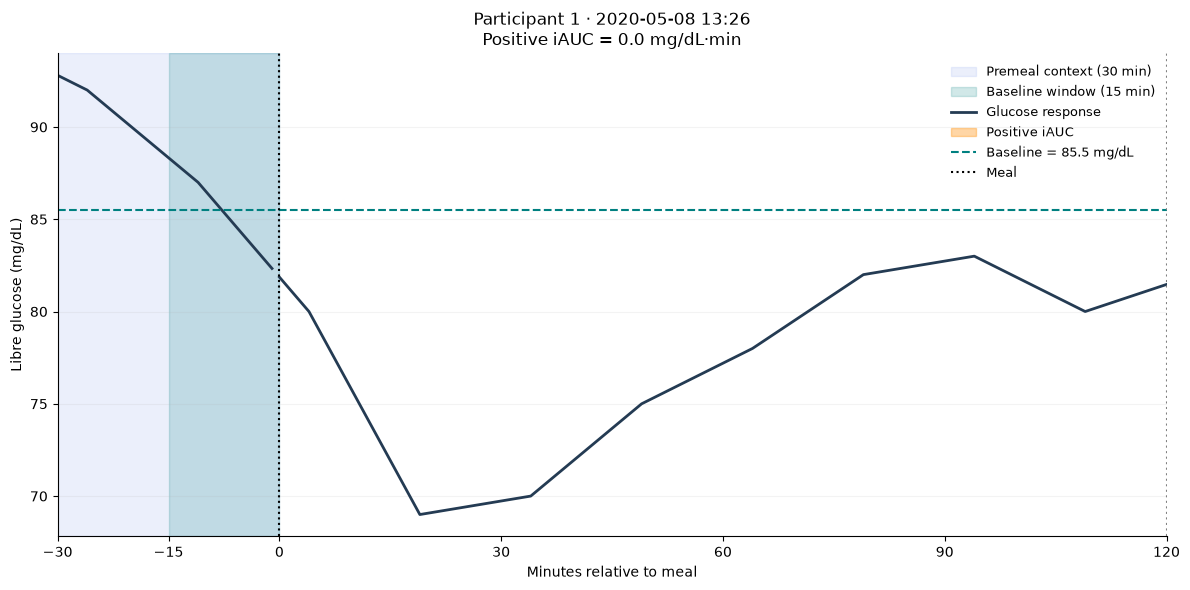

In [29]:
# Select a meal from your existing results.
subject = 1
meal_number = 21


meal = (
    meal_outcomes.loc[meal_outcomes["subject"] == subject]
    .sort_values("event_timestamp")
    .iloc[meal_number]
)

meal_time = pd.Timestamp(meal["event_timestamp"])
baseline = meal["baseline_capped"]
iauc = meal["iauc_capped"]

# Retrieve glucose for the existing context and response windows.
glucose = (
    frames[subject]
    .set_index("Timestamp")["Libre GL"]
    .clip(upper=400)
)

context_times = pd.date_range(
    meal_time - pd.Timedelta(minutes=PREMEAL_MINUTES),
    periods=PREMEAL_MINUTES,
    freq="min",
)
response_times = pd.date_range(
    meal_time,
    periods=RESPONSE_MINUTES + 1,
    freq="min",
)

context = glucose.reindex(context_times)
response = fill_short_internal_gaps(
    glucose.reindex(response_times),
    max_gap=MAX_MISSING_RUN,
)

context_minutes = np.arange(-PREMEAL_MINUTES, 0)
response_minutes = np.arange(RESPONSE_MINUTES + 1)

fig, ax = plt.subplots(figsize=(12, 6))

# Premeal windows.
ax.axvspan(
    -PREMEAL_MINUTES, 0,
    color="royalblue", alpha=0.10,
    label=f"Premeal context ({PREMEAL_MINUTES} min)",
)
ax.axvspan(
    -BASELINE_MINUTES, 0,
    color="teal", alpha=0.18,
    label=f"Baseline window ({BASELINE_MINUTES} min)",
)

# Glucose curve.
ax.plot(context_minutes, context, color="#243b53", linewidth=2)
ax.plot(
    response_minutes, response,
    color="#243b53", linewidth=2,
    label="Glucose response",
)

# Shade positive area, including exact baseline crossings.
ax.fill_between(
    response_minutes,
    baseline,
    response.to_numpy(),
    where=response.to_numpy() >= baseline,
    interpolate=True,
    color="darkorange", alpha=0.35,
    label="Positive iAUC",
)

ax.axhline(
    baseline, color="teal", linestyle="--",
    label=f"Baseline = {baseline:.1f} mg/dL",
)
ax.axvline(0, color="black", linestyle=":", label="Meal")
ax.axvline(RESPONSE_MINUTES, color="gray", linestyle=":")

ax.set(
    xlabel="Minutes relative to meal",
    ylabel="Libre glucose (mg/dL)",
    title=(
        f"Participant {subject} · {meal_time:%Y-%m-%d %H:%M}\n"
        f"Positive iAUC = {iauc:,.1f} mg/dL·min"
    ),
    xlim=(-PREMEAL_MINUTES, RESPONSE_MINUTES),
)
ax.set_xticks([-30, -15, 0, 30, 60, 90, 120])
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.15)
ax.legend(frameon=False, fontsize=9)

fig.tight_layout()
fig.savefig(
    OUT_DIR / f"meal_iauc_subject_{subject}_{meal_time:%Y%m%d_%H%M}.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## 6. Build features on the same 1,139 meals
All features are joined to `meal_outcomes` with validated one-to-one (meal level) or many-to-one (participant level) merges so no meal can be duplicated or dropped.

**Food macros.** Values above 500 g are set to missing and fiber above 50 g is set to missing (modeling copy only)

**Pre-meal context** (30 min before the meal, ≥24 valid minutes required, otherwise missing and imputed inside the CV pipeline): glucose mean, slope, last value and SD; mean heart rate; physical-activity signals. Because activity schemas differ across files, the raw channels (`METs`/10, `Steps`, `Calories_Activity`, `Intensity`) are kept only if enough meals have them, and a schema-independent `pre_activity_z` is added: the pre-meal mean of each person's own z-scored energy-expenditure channel (METs if present, else Calories_Activity).

**Extra features:** meal type, time of day (sin/cos), weekend, and hours since the previous food entry.

#### FEATURE SET: Food macros (M1)

In [30]:

food_tables = []
for subject, frame in frames.items():
    labels = frame["Meal Type"].astype("string").str.strip()
    is_food = labels.notna() & labels.ne("")
    food = frame.loc[is_food, ["Timestamp", "Calories", *macro_columns]].rename(
        columns={"Timestamp": "event_timestamp"})
    food.insert(0, "subject", subject)
    food_tables.append(food)
food_table = pd.concat(food_tables, ignore_index=True)

model_df = meal_outcomes.merge(
    food_table, on=["subject", "event_timestamp"],
    how="left", validate="one_to_one", indicator=True)

model_df = model_df.drop(columns="_merge")

# Diagnostic only: calorie vs macro-energy disagreement (review flag, not a filter)
macro_energy = 4 * model_df["Carbs"] + 4 * model_df["Protein"] + 9 * model_df["Fat"]
energy_diff = (model_df["Calories"] - macro_energy).abs() / model_df["Calories"].where(model_df["Calories"] > 0)
print("Meals with >30% calorie/macro-energy disagreement (kept):", int((energy_diff > 0.30).sum()))

cleaning_log = {}
for column in macro_columns:
    cleaning_log[f"{column} > 500 g -> NaN"] = int(model_df[column].gt(500).sum())
    model_df.loc[model_df[column].gt(500), column] = np.nan
fiber_over_50 = model_df["Fiber"].gt(50)
cleaning_log["Fiber > 50 g -> NaN"] = int(fiber_over_50.sum())
model_df.loc[fiber_over_50, "Fiber"] = np.nan

print("\nMacro cleaning actions:")
print(pd.Series(cleaning_log).to_string())
print("\nMissing macro values after cleaning:")
print(model_df[macro_columns].isna().sum().to_string())
print("\nMacro distributions:")
print(model_df[macro_columns].describe(percentiles=[0.5, 0.95]).round(2).to_string())

Meals with >30% calorie/macro-energy disagreement (kept): 30

Macro cleaning actions:
Carbs > 500 g -> NaN      1
Protein > 500 g -> NaN    0
Fat > 500 g -> NaN        1
Fiber > 500 g -> NaN      8
Fiber > 50 g -> NaN       7

Missing macro values after cleaning:
Carbs       1
Protein     0
Fat         1
Fiber      16

Macro distributions:
         Carbs  Protein      Fat    Fiber
count  1138.00  1139.00  1138.00  1123.00
mean     56.19    33.90    21.62     4.68
std      30.72    25.09    16.02     5.13
min       0.00     0.00     0.00     0.00
50%      66.00    22.00    15.00     4.00
95%      94.00    84.00    44.00    13.00
max     204.00   148.00   110.00    30.00


#### FEATURE SET: Pre-meal glucose, heart rate, physical activity (M2)

In [31]:

def premeal_features(subject, frame, events):
    series = frame.set_index("Timestamp")
    glucose = series["Libre GL"].clip(upper=400)

    signals = {
        "pre_hr_mean": series["HR"],
        "pre_mets_mean": series["METs"] / 10,          # Fitbit METs x 10 encoding
        "pre_steps_mean": series["Steps"],
        "pre_actcal_mean": series["Calories_Activity"],
        "pre_intensity_mean": series["Intensity"],
    }

    # Schema-independent activity: within-person z-score of one energy channel
    channel = next((c for c in ["METs", "Calories_Activity"] if series[c].notna().any()), None)
    if channel is not None:
        spread = series[channel].std(ddof=0)
        if spread and spread > 0:
            signals["pre_activity_z"] = (series[channel] - series[channel].mean()) / spread

    rows = []
    for event in events.itertuples(index=False):
        times = pd.date_range(event.event_timestamp - pd.Timedelta(minutes=PREMEAL_MINUTES),
                              periods=PREMEAL_MINUTES, freq="min")
        window = glucose.reindex(times)
        available = window.notna().to_numpy()
        enough = available.sum() >= PREMEAL_MIN_VALID

        row = {"subject": subject, "event_timestamp": event.event_timestamp}
        row["pre_glucose_mean"] = float(window.mean()) if enough else np.nan
        row["pre_glucose_sd"] = float(window.std(ddof=0)) if enough else np.nan
        row["pre_glucose_slope"] = (
            float(np.polyfit(np.arange(PREMEAL_MINUTES)[available], window.to_numpy()[available], 1)[0])
            if enough else np.nan)
        last = window.dropna()
        row["pre_glucose_last"] = (
            float(last.iloc[-1])
            if len(last) and (times[-1] - last.index[-1]) <= pd.Timedelta(minutes=5) else np.nan)

        for name, signal in signals.items():
            values = signal.reindex(times).dropna()
            row[name] = float(values.mean()) if len(values) >= PREMEAL_MIN_VALID else np.nan
        rows.append(row)
    return pd.DataFrame(rows)


premeal = pd.concat(
    [premeal_features(subject, frames[subject], meal_outcomes.loc[meal_outcomes["subject"].eq(subject)])
     for subject in meal_outcomes["subject"].unique()],
    ignore_index=True)

model_df = model_df.merge(premeal, on=["subject", "event_timestamp"], how="left", validate="one_to_one")
for column in ["pre_hr_mean", "pre_mets_mean", "pre_steps_mean", "pre_actcal_mean",
               "pre_intensity_mean", "pre_activity_z"]:
    if column not in model_df.columns:
        model_df[column] = np.nan

premeal_cols = ["pre_glucose_mean", "pre_glucose_slope", "pre_glucose_last", "pre_glucose_sd", "pre_hr_mean"]
activity_cols = ["pre_mets_mean", "pre_steps_mean", "pre_actcal_mean", "pre_intensity_mean", "pre_activity_z"]

print("Rows after pre-meal join:", len(model_df))
print("\nMissing pre-meal / activity values:")
print(model_df[premeal_cols + activity_cols].isna().sum().to_string())
print("\nDistributions:")
print(model_df[premeal_cols + activity_cols].describe().round(2).T.to_string())

# ---- Meal context ------------------------------------------------------------
hour = model_df["event_timestamp"].dt.hour + model_df["event_timestamp"].dt.minute / 60
model_df["meal_hour_sin"] = np.sin(2 * np.pi * hour / 24)
model_df["meal_hour_cos"] = np.cos(2 * np.pi * hour / 24)
model_df["is_weekend"] = (model_df["event_timestamp"].dt.dayofweek >= 5).astype(float)
for meal in ["breakfast", "lunch", "dinner"]:           # 'snack' is the reference level
    model_df[f"meal_{meal}"] = model_df["meal_type"].eq(meal).astype(float)
model_df["hours_since_prev_food"] = (model_df["previous_gap_min"] / 60).clip(upper=12)

meal_context_cols = ["meal_hour_sin", "meal_hour_cos", "is_weekend",
                     "meal_breakfast", "meal_lunch", "meal_dinner", "hours_since_prev_food"]
print("\nMeal-context features (missing counts):")
print(model_df[meal_context_cols].isna().sum().to_string())

Rows after pre-meal join: 1139

Missing pre-meal / activity values:
pre_glucose_mean         0
pre_glucose_slope        0
pre_glucose_last         0
pre_glucose_sd           0
pre_hr_mean             68
pre_mets_mean          266
pre_steps_mean        1139
pre_actcal_mean          5
pre_intensity_mean     878
pre_activity_z           5

Distributions:
                     count    mean    std    min    25%    50%     75%     max
pre_glucose_mean    1139.0  102.17  33.52  40.00  81.34  95.16  115.94  330.99
pre_glucose_slope   1139.0   -0.01   0.43  -3.46  -0.17   0.01    0.18    2.19
pre_glucose_last    1139.0  102.88  32.92  40.00  82.00  97.00  117.07  329.47
pre_glucose_sd      1139.0    2.69   2.79   0.00   0.96   1.82    3.40   29.96
pre_hr_mean         1071.0   83.84  11.40  53.57  76.58  83.37   91.07  126.97
pre_mets_mean        873.0    2.18   0.84   1.00   1.57   2.01    2.63    5.93
pre_steps_mean         0.0     NaN    NaN    NaN    NaN    NaN     NaN     NaN
pre_actcal_mea

/var/folders/_b/hbc99gnj4kl9q9mc9c9xr0yw0000gn/T/ipykernel_8399/4229026485.py:70: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  model_df["is_weekend"] = (model_df["event_timestamp"].dt.dayofweek >= 5).astype(float)


In [32]:
# Dropping pre_steps_mean and pre_intensity_mean: pre_steps_mean carries zero variance (100% NaN), and pre_intensity_mean is missing in over three-quarters of meals.
model_df = model_df.drop(columns=["pre_steps_mean", "pre_intensity_mean"])

#### FEATURE SET: Blood biomarkers / demographics (M3)

In [33]:
health_columns = ["Age", "BMI", "A1c PDL (Lab)", "Fasting GLU - PDL (Lab)", "Insulin"]
health_columns += [c for c in ["Triglycerides", "Cholesterol", "HDL", "LDL (Cal)", "VLDL (Cal)"]
                       if c in bio.columns]

health = bio[["subject", *health_columns]].copy()
for column in health_columns:
    health[column] = pd.to_numeric(health[column], errors="coerce")

model_df = model_df.merge(health, on="subject", how="left", validate="many_to_one", indicator=True)
assert model_df["_merge"].eq("both").all(), "Missing participant metadata"
model_df = model_df.drop(columns="_merge")
print("Blood/demographic features:", health_columns)
print("Missing values per feature (meals):")
print(model_df[health_columns].isna().sum().to_string()) # sub-12 LDL and VLDL were already set to NaN in the cleaning step above, so this is expected.


Blood/demographic features: ['Age', 'BMI', 'A1c PDL (Lab)', 'Fasting GLU - PDL (Lab)', 'Insulin', 'Triglycerides', 'Cholesterol', 'HDL', 'LDL (Cal)', 'VLDL (Cal)']
Missing values per feature (meals):
Age                         0
BMI                         0
A1c PDL (Lab)               0
Fasting GLU - PDL (Lab)     0
Insulin                     0
Triglycerides               0
Cholesterol                 0
HDL                         0
LDL (Cal)                  31
VLDL (Cal)                 31


#### FEATURE SET: Gut-health features (M4)

In [34]:
gut_numeric = gut[["subject", *gut_columns]].copy()
for column in gut_columns:
    gut_numeric[column] = pd.to_numeric(gut_numeric[column], errors="coerce")

gut_observed = gut_numeric.loc[gut_numeric[gut_columns].notna().any(axis=1)].copy()
gut_features = [c for c in gut_columns if gut_observed[c].nunique(dropna=True) > 1]
gut_constant = sorted(set(gut_columns) - set(gut_features))

model_df = model_df.merge(gut_observed[["subject", *gut_features]],
                          on="subject", how="left", validate="many_to_one")
model_df["has_gut_profile"] = model_df["subject"].isin(gut_observed["subject"])

print(f"\nGut features kept: {len(gut_features)} | constant/empty columns dropped: {gut_constant}")
print("Meals with a gut profile:", int(model_df["has_gut_profile"].sum()), "of", len(model_df),
      "| participants:", model_df.loc[model_df["has_gut_profile"], "subject"].nunique(),
      "of", model_df["subject"].nunique())


Gut features kept: 22 | constant/empty columns dropped: []
Meals with a gut profile: 1055 of 1139 | participants: 40 of 43


In [35]:
# ---- Targets (single dataframe: identifiers + targets + all features) --------
model_df["y_raw"] = model_df["iauc_capped"]
model_df["y_log"] = np.log1p(model_df["y_raw"])         

# Feature coverage check: drop low-coverage premeal/activity features
activity_cols = ["pre_mets_mean",  "pre_actcal_mean",  "pre_activity_z"]
candidate_features = {
    **{c: "premeal" for c in premeal_cols},
    **{c: "activity" for c in activity_cols},
}

coverage = pd.DataFrame({
    "group": pd.Series(candidate_features),
    "coverage_pct": (100 * model_df[list(candidate_features)].notna().mean()).round(1),
})
coverage["kept"] = coverage["coverage_pct"] >= 100 * MIN_FEATURE_COVERAGE
print(f"Coverage of pre-meal / activity features (threshold {100 * MIN_FEATURE_COVERAGE:.0f}%):")
print(coverage.to_string())

premeal_cols = [c for c in premeal_cols if coverage.loc[c, "kept"]]
activity_cols = [c for c in activity_cols if coverage.loc[c, "kept"]]

identifiers = ["subject", "event_timestamp", "meal_type"]
targets = ["y_raw", "y_log"]
all_features = list(dict.fromkeys(
    macro_columns + premeal_cols + activity_cols + meal_context_cols + health_columns + gut_features))
model_df = model_df[identifiers + targets + ["has_gut_profile"] + all_features].reset_index(drop=True)

assert not model_df.duplicated(["subject", "event_timestamp"]).any()
print("\nSingle modeling dataframe:", model_df.shape,
      "| meals:", len(model_df), "| participants:", model_df["subject"].nunique())
display(model_df.head(5))
print("\nFeatures with any missing values (count of meals):")
missing = model_df[all_features].isna().sum()
print(missing[missing > 0].to_string() if (missing > 0).any() else "none")
model_df.to_csv(OUT_DIR / "model_dataframe.csv", index=False)

Coverage of pre-meal / activity features (threshold 40%):
                      group  coverage_pct  kept
pre_glucose_mean    premeal         100.0  True
pre_glucose_slope   premeal         100.0  True
pre_glucose_last    premeal         100.0  True
pre_glucose_sd      premeal         100.0  True
pre_hr_mean         premeal          94.0  True
pre_mets_mean      activity          76.6  True
pre_actcal_mean    activity          99.6  True
pre_activity_z     activity          99.6  True

Single modeling dataframe: (1139, 57) | meals: 1139 | participants: 43


,subject,event_timestamp,meal_type,y_raw,y_log,has_gut_profile,Carbs,Protein,Fat,Fiber,pre_glucose_mean,pre_glucose_slope,pre_glucose_last,pre_glucose_sd,pre_hr_mean,pre_mets_mean,pre_actcal_mean,pre_activity_z,meal_hour_sin,meal_hour_cos,is_weekend,meal_breakfast,meal_lunch,meal_dinner,hours_since_prev_food,Age,BMI,A1c PDL (Lab),Fasting GLU - PDL (Lab),Insulin,Triglycerides,Cholesterol,HDL,LDL (Cal),VLDL (Cal),Gut Lining Health,LPS Biosynthesis Pathways,"Biofilm, Chemotaxis, and Virulence Pathways",TMA Production Pathways,Ammonia Production Pathways,Metabolic Fitness,Active Microbial Diversity,Butyrate Production Pathways,Flagellar Assembly Pathways,Putrescine Production Pathways,Uric Acid Production Pathways,Bile Acid Metabolism Pathways,Inflammatory Activity,Gut Microbiome Health,Digestive Efficiency,Protein Fermentation,Gas Production,Methane Gas Production Pathways,Sulfide Gas Production Pathways,Oxalate Metabolism Pathways,Salt Stress Pathways,Microbiome-Induced Stress
0,1,2020-05-01 14:23:00,lunch,1200.451125,7.091285,True,85.0,88.0,54.2,12.0,76.751111,-0.450278,70.200000,3.929412,89.500000,3.166667,3.319933,0.709268,-5.842497e-01,-0.811574,0.0,0.0,1.0,0.0,NaN,27,22.265239,5.4,91,2.5,67,216,74,130.0,13.0,2.0,2.0,1.0,2.0,1.0,3.0,2.0,3.0,2.0,2.0,2.0,3.0,2.0,3.0,1.0,1.0,2.0,3.0,1.0,1.0,3.0,2.0
1,1,2020-05-01 20:48:00,dinner,1745.000000,7.465083,True,18.0,0.0,0.0,0.0,84.220000,-0.044271,84.200000,0.556217,87.233333,2.433333,2.551107,0.254260,-7.431448e-01,0.669131,0.0,0.0,0.0,1.0,6.416667,27,22.265239,5.4,91,2.5,67,216,74,130.0,13.0,2.0,2.0,1.0,2.0,1.0,3.0,2.0,3.0,2.0,2.0,2.0,3.0,2.0,3.0,1.0,1.0,2.0,3.0,1.0,1.0,3.0,2.0
2,1,2020-05-02 00:15:00,snack,1283.160000,7.157860,True,24.0,0.0,2.0,0.0,86.666667,-0.329996,81.400000,2.870798,64.233333,1.886667,1.977981,-0.084929,6.540313e-02,0.997859,1.0,0.0,0.0,0.0,3.450000,27,22.265239,5.4,91,2.5,67,216,74,130.0,13.0,2.0,2.0,1.0,2.0,1.0,3.0,2.0,3.0,2.0,2.0,2.0,3.0,2.0,3.0,1.0,1.0,2.0,3.0,1.0,1.0,3.0,2.0
3,1,2020-05-02 08:18:00,breakfast,1528.923160,7.332973,True,66.0,22.0,10.5,0.0,86.180000,0.134149,87.933333,1.330903,59.433333,1.723333,1.806743,-0.186271,8.241262e-01,-0.566406,1.0,1.0,0.0,0.0,8.050000,27,22.265239,5.4,91,2.5,67,216,74,130.0,13.0,2.0,2.0,1.0,2.0,1.0,3.0,2.0,3.0,2.0,2.0,2.0,3.0,2.0,3.0,1.0,1.0,2.0,3.0,1.0,1.0,3.0,2.0
4,1,2020-05-02 12:00:00,lunch,893.457983,6.796218,True,89.0,17.0,42.0,3.0,83.500000,0.010011,82.200000,0.869866,97.033333,3.430000,3.596012,0.872657,1.224647e-16,-1.000000,1.0,0.0,1.0,0.0,3.700000,27,22.265239,5.4,91,2.5,67,216,74,130.0,13.0,2.0,2.0,1.0,2.0,1.0,3.0,2.0,3.0,2.0,2.0,2.0,3.0,2.0,3.0,1.0,1.0,2.0,3.0,1.0,1.0,3.0,2.0



Features with any missing values (count of meals):
Carbs                                            1
Fat                                              1
Fiber                                           16
pre_hr_mean                                     68
pre_mets_mean                                  266
pre_actcal_mean                                  5
pre_activity_z                                   5
hours_since_prev_food                           24
LDL (Cal)                                       31
VLDL (Cal)                                      31
Gut Lining Health                               84
LPS Biosynthesis Pathways                       84
Biofilm, Chemotaxis, and Virulence Pathways     84
TMA Production Pathways                         84
Ammonia Production Pathways                     84
Metabolic Fitness                               84
Active Microbial Diversity                      84
Butyrate Production Pathways                    84
Flagellar Assembly Pathways   

In [36]:
# ---- M1 to M4 = column selections from the same dataframe -------------------
M1 = macro_columns
M2 = M1 + premeal_cols + activity_cols + meal_context_cols
M3 = M2 + health_columns
M4 = M3 + gut_features

FEATURE_SETS = {"M1": M1, "M2": M2, "M3": M3, "M3_gutmatched": M3, "M4": M4}

full_data = model_df.reset_index(drop=True)
matched_data = model_df.loc[model_df["has_gut_profile"]].reset_index(drop=True)
DATASETS = {"M1": full_data, "M2": full_data, "M3": full_data,
            "M3_gutmatched": matched_data, "M4": matched_data}

overview = pd.DataFrame([{
    "set": name,
    "features": len(cols),
    "meals": len(DATASETS[name]),
    "participants": DATASETS[name]["subject"].nunique(),
    "missing_cells": int(DATASETS[name][cols].isna().sum().sum()),
    "missing_pct": round(100 * DATASETS[name][cols].isna().mean().mean(), 2),
} for name, cols in FEATURE_SETS.items()])
print("Feature sets:")
print(overview.to_string(index=False))

for name, cols in [("M1", M1), ("M2 adds", [c for c in M2 if c not in M1]),
                   ("M3 adds", health_columns), ("M4 adds", gut_features)]:
    print(f"\n{name} ({len(cols)}): {cols}")

print("\nM3_gutmatched is M3 on the gut-matched meals & subjects; compare it with M4 for a fair gut effect.")

Feature sets:
          set  features  meals  participants  missing_cells  missing_pct
           M1         4   1139            43             18         0.40
           M2        19   1139            43            386         1.78
           M3        29   1139            43            448         1.36
M3_gutmatched        29   1055            40            419         1.37
           M4        51   1055            40            419         0.78

M1 (4): ['Carbs', 'Protein', 'Fat', 'Fiber']

M2 adds (15): ['pre_glucose_mean', 'pre_glucose_slope', 'pre_glucose_last', 'pre_glucose_sd', 'pre_hr_mean', 'pre_mets_mean', 'pre_actcal_mean', 'pre_activity_z', 'meal_hour_sin', 'meal_hour_cos', 'is_weekend', 'meal_breakfast', 'meal_lunch', 'meal_dinner', 'hours_since_prev_food']

M3 adds (10): ['Age', 'BMI', 'A1c PDL (Lab)', 'Fasting GLU - PDL (Lab)', 'Insulin', 'Triglycerides', 'Cholesterol', 'HDL', 'LDL (Cal)', 'VLDL (Cal)']

M4 adds (22): ['Gut Lining Health', 'LPS Biosynthesis Pathways', '

## 7. Models and cross-validation engine

* **Ridge:** `Pipeline(median imputer → StandardScaler → Ridge)`, `alpha_grid = logspace(-3, 6, 19)`.
* **XGBoost:** `XGBRegressor(max_depth=1, n_estimators=80, learning_rate=0.2, reg_alpha=1, reg_lambda=0)` tuned over `max_depth ∈ {1,2,3}`, `n_estimators ∈ {50,80,100}`, `learning_rate ∈ {0.1,0.2,0.3}` (trees handle missing values natively, so no imputer).

For every feature set, each of these runs with **`y_raw`** :

1. **Outer CV:** `GroupKFold(5)` by participant, so every meal gets exactly one out-of-fold prediction from a model that never saw that participant.
2. **Inner CV:** `GridSearchCV(..., scoring="neg_mean_squared_error", cv=GroupKFold(5))` on the training participants only.

In [37]:
# ---- Models ---------------------------
alpha_grid = np.logspace(-3, 6, 19)

food_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("ridge", Ridge()),
])
ridge_grid = {"ridge__alpha": alpha_grid}


mdl = xgb.XGBRegressor(max_depth=1, n_estimators=80, learning_rate=0.2,
                        reg_alpha=1, reg_lambda=0, random_state=SEED, n_jobs=1)
xgb_grid = {"max_depth": [1, 2, 3], "n_estimators": [50, 80, 100],
                "learning_rate": [0.1, 0.2, 0.3]}

MODEL_SPECS = {
    "Ridge": dict(estimator=food_pipeline, grid=ridge_grid,
                  scoring="neg_mean_squared_error", targets=["y_raw"]),
    "XGBoost": dict(estimator=mdl, grid=xgb_grid,
                    scoring="neg_mean_squared_error", targets=["y_raw"])
}

# Label shown in tables/plots for each (model, target, back-transform)
PRIMARY_RUNS = [
    ("Ridge", "y_raw", "raw", "Ridge (raw)"),
    ("XGBoost", "y_raw", "raw", "XGBoost (raw)")
]
RUN_LABELS = [label for *_, label in PRIMARY_RUNS]


In [38]:
# Fix this split and reuse it for subsequent feature-set comparisons.
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED,
)

train_index, validation_index = next(
    splitter.split(
        meal_outcomes,
        groups=meal_outcomes["subject"],
    )
)

train_meals = meal_outcomes.iloc[train_index].copy()
validation_meals = meal_outcomes.iloc[validation_index].copy()

# Confirm that no participant appears on both sides.
train_subjects = set(train_meals["subject"])
validation_subjects = set(validation_meals["subject"])
assert train_subjects.isdisjoint(validation_subjects)

y_train = train_meals["iauc_capped"]
y_validation = validation_meals["iauc_capped"]

# Learn the constant using training outcomes only.
training_mean = float(y_train.mean())
prediction = np.full(len(y_validation), training_mean)

baseline_predictions = validation_meals[
    ["subject", "event_timestamp", "meal_type", "iauc_capped"]
].copy()
baseline_predictions["prediction"] = prediction
baseline_predictions["absolute_error"] = np.abs(y_validation - prediction)

# Equal participant weighting complements the pooled meal-level MAE.
participant_mae = baseline_predictions.groupby("subject")[
    "absolute_error"
].mean()

print("Training participants:", len(train_subjects))
print("Validation participants:", len(validation_subjects))
print("Training meals:", len(train_meals))
print("Validation meals:", len(validation_meals))
print("Validation participant IDs:", sorted(validation_subjects))

print("\nTraining-mean prediction:", round(training_mean, 2))
print("Validation RMSE:",
      round(np.sqrt(mean_squared_error(y_validation, prediction)), 2))
print("Validation MAE:",
      round(mean_absolute_error(y_validation, prediction), 2))
print("Validation R²:",
      round(r2_score(y_validation, prediction), 3))
print("Mean participant MAE:", round(participant_mae.mean(), 2))

print("\nValidation MAE by participant:")
print(participant_mae.round(2).to_string())

Training participants: 34
Validation participants: 9
Training meals: 924
Validation meals: 215
Validation participant IDs: [17, 27, 33, 34, 35, 38, 42, 45, 46]

Training-mean prediction: 3156.6
Validation RMSE: 3940.9
Validation MAE: 2958.7
Validation R²: -0.023
Mean participant MAE: 2847.18

Validation MAE by participant:
subject
17    1737.62
27    2027.32
33    4279.70
34    2035.04
35    4378.03
38    2375.77
42    1950.32
45    3642.76
46    3198.09


In [39]:
def best_params_dict(search):
    return {k.split("__")[-1]: v for k, v in search.best_params_.items()}

# ---- Fixed holdout with grouped training CV -------------------------------
def run_cv(set_name, columns, data, verbose=True):
    """Tune on training participants; predict the fixed validation participants."""

    train_mask = data["subject"].isin(train_subjects)
    valid_mask = data["subject"].isin(validation_subjects)

    train = data.loc[train_mask].copy()
    valid = data.loc[valid_mask].copy()
    prediction_rows, param_rows = [], []

    base = valid[
        ["subject", "event_timestamp", "meal_type"]
    ].copy()
    base["feature_set"] = set_name
    base["fold"] = 1
    base["y_true"] = valid["y_raw"].to_numpy()

    def add(model, target, variant, predicted):
        prediction_rows.append(
            base.assign(
                model=model,
                target=target,
                variant=variant,
                y_pred=np.asarray(predicted),
            )
        )

    # Learn the baseline from training outcomes only.
    add(
        "Baseline",
        "-",
        "training_mean",
        np.full(len(valid), float(train["y_raw"].mean())),
    )

    inner_cv = GroupKFold(n_splits=INNER_FOLDS)

    for name, spec in MODEL_SPECS.items():
        for target in spec["targets"]:
            search = GridSearchCV(
                estimator=clone(spec["estimator"]),
                param_grid=spec["grid"],
                scoring=spec["scoring"],
                cv=inner_cv,
                n_jobs=-1,
                refit=True,
                error_score="raise",
            )

            search.fit(
                train[columns],
                train[target],
                groups=train["subject"],
            )
            
            predicted = search.predict(valid[columns])
            add(name, target, "raw", predicted)
            if name == 'Ridge':
                ridge_model = search.best_estimator_.named_steps["ridge"]
                lasso_coefficients = pd.Series(ridge_model.coef_, index=columns)
                top_10_coef = lasso_coefficients.abs().sort_values(ascending=False).head(10)
                print("\nTop 10 features with the largest coefficients:")
                print(top_10_coef)
            elif name == 'XGBoost':
                xgb.plot_importance(
                search.best_estimator_,
                max_num_features=10,      # Limit to the top 10 features
                importance_type='gain',   # Options: 'weight', 'gain', 'cover', 'total_gain', 'total_cover'
                height=0.5,               # Adjust bar thickness
                title='Top 10 Most Important Features'
                )
        
                plt.tight_layout()
                plt.show()
            param_rows.append({
                "feature_set": set_name,
                "fold": 1,
                "model": name,
                "target": target,
                "inner_cv_score": search.best_score_,
                **best_params_dict(search),
            })

    if verbose:
        print(
            f"  [{set_name}] done "
            f"(train {len(train)} meals / "
            f"{train['subject'].nunique()} participants, "
            f"validation {len(valid)} meals / "
            f"{valid['subject'].nunique()} participants)"
        )
    

    return (
        pd.concat(prediction_rows, ignore_index=True),
        pd.DataFrame(param_rows),
    )


# ---- Evaluation -----------------------------------------------------------
def evaluate(predictions, baseline_participant_mae=None):
    """Calculate validation metrics for one model and feature set."""
    y = predictions["y_true"].to_numpy()
    p = predictions["y_pred"].to_numpy()

    participant_mae = (
        predictions.assign(absolute_error=np.abs(y - p))
        .groupby("subject")["absolute_error"]
        .mean()
    )

    results = {
        "RMSE": float(np.sqrt(mean_squared_error(y, p))),
        "MAE": float(mean_absolute_error(y, p)),
        "R2": float(r2_score(y, p)),
        "mean_participant_MAE": float(participant_mae.mean()),
        "negative_predictions": int((p < 0).sum()),
    }

    if baseline_participant_mae is not None:
        joined = pd.concat(
            [
                participant_mae.rename("model"),
                baseline_participant_mae.rename("baseline"),
            ],
            axis=1,
        ).dropna()

        results["pct_participants_better_than_mean"] = float(
            100 * (joined["model"] < joined["baseline"]).mean()
        )

    return results


def summarize(predictions):
    """Summarize each model on its feature set's validation meals."""
    rows = []

    for feature_set, block in predictions.groupby(
        "feature_set", sort=False
    ):
        baseline = block.loc[
            (block["model"] == "Baseline")
            & (block["variant"] == "training_mean")
        ]

        baseline_participant_mae = (
            baseline.assign(
                absolute_error=(
                    baseline["y_true"] - baseline["y_pred"]
                ).abs()
            )
            .groupby("subject")["absolute_error"]
            .mean()
        )

        for (model, target, variant), group in block.groupby(
            ["model", "target", "variant"], sort=False
        ):
            rows.append({
                "feature_set": feature_set,
                "model": model,
                "target": target,
                "variant": variant,
                **evaluate(group, baseline_participant_mae),
            })

    return pd.DataFrame(rows)




=== M1: 4 features, 1139 meals, 43 participants ===

Top 10 features with the largest coefficients:
Carbs      1005.032230
Fiber       439.010391
Protein     282.293147
Fat         180.180036
dtype: float64


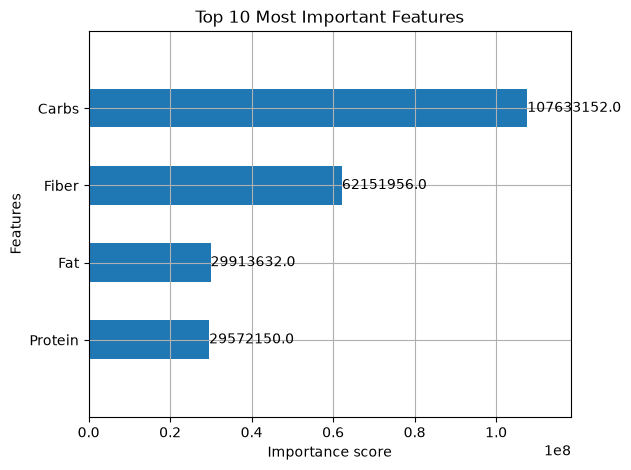

  [M1] done (train 924 meals / 34 participants, validation 215 meals / 9 participants)

M1 pooled out-of-fold results (0s):
   model target       variant     RMSE      MAE     R2  mean_participant_MAE
Baseline      - training_mean 3940.900 2958.698 -0.023              2847.182
   Ridge  y_raw           raw 3723.099 2741.599  0.087              2630.829
 XGBoost  y_raw           raw 3640.568 2718.076  0.127              2613.353

=== M2: 19 features, 1139 meals, 43 participants ===

Top 10 features with the largest coefficients:
pre_glucose_last         13941.014092
pre_glucose_mean         13876.144688
pre_glucose_slope         2354.234929
Carbs                      872.272202
hours_since_prev_food      777.889234
meal_breakfast             609.982768
pre_glucose_sd             513.621306
meal_lunch                 481.313067
Protein                    462.718990
meal_hour_sin              351.173655
dtype: float64


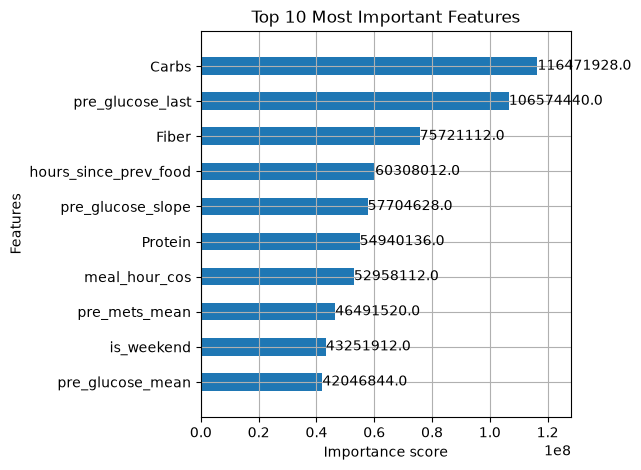

  [M2] done (train 924 meals / 34 participants, validation 215 meals / 9 participants)

M2 pooled out-of-fold results (1s):
   model target       variant     RMSE      MAE     R2  mean_participant_MAE
Baseline      - training_mean 3940.900 2958.698 -0.023              2847.182
   Ridge  y_raw           raw 3063.113 2282.874  0.382              2210.873
 XGBoost  y_raw           raw 3206.073 2314.332  0.323              2222.670

=== M3: 29 features, 1139 meals, 43 participants ===

Top 10 features with the largest coefficients:
Carbs                      904.367682
A1c PDL (Lab)              725.368481
pre_glucose_mean           466.023897
BMI                        455.961419
Triglycerides              452.287849
pre_glucose_slope          447.626603
Insulin                    404.075188
Protein                    388.795618
Fasting GLU - PDL (Lab)    359.107040
HDL                        345.827764
dtype: float64


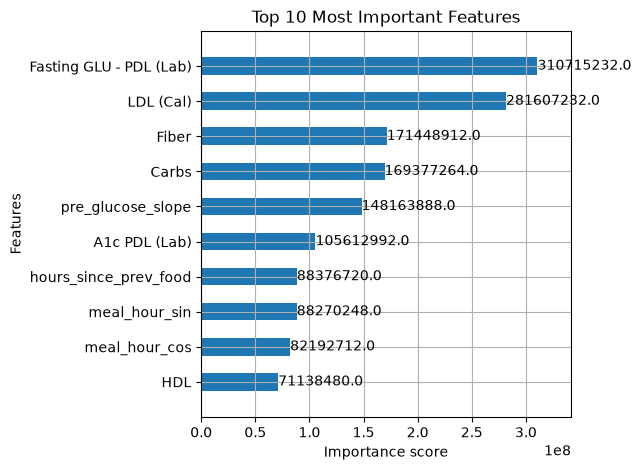

  [M3] done (train 924 meals / 34 participants, validation 215 meals / 9 participants)

M3 pooled out-of-fold results (1s):
   model target       variant     RMSE      MAE     R2  mean_participant_MAE
Baseline      - training_mean 3940.900 2958.698 -0.023              2847.182
   Ridge  y_raw           raw 3260.559 2426.835  0.299              2352.710
 XGBoost  y_raw           raw 3319.175 2608.080  0.274              2538.714

=== M3_gutmatched: 29 features, 1055 meals, 40 participants ===

Top 10 features with the largest coefficients:
Carbs                      674.802631
A1c PDL (Lab)              519.105594
Triglycerides              388.870361
pre_glucose_slope          388.433123
Fasting GLU - PDL (Lab)    370.837872
HDL                        297.071464
Protein                    275.072437
pre_glucose_mean           271.299991
BMI                        266.341359
Insulin                    261.805240
dtype: float64


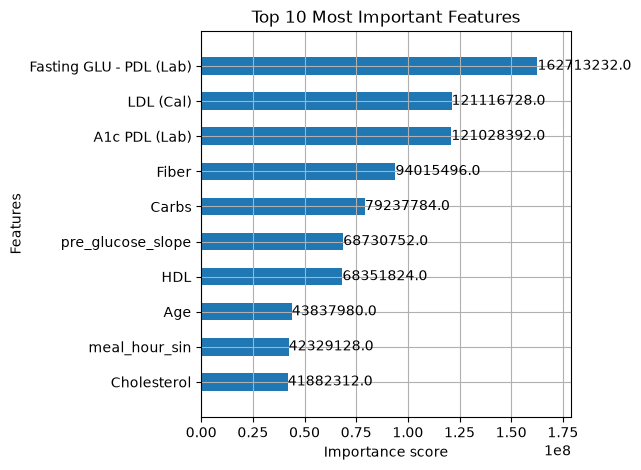

  [M3_gutmatched] done (train 840 meals / 31 participants, validation 215 meals / 9 participants)

M3_gutmatched pooled out-of-fold results (1s):
   model target       variant     RMSE      MAE     R2  mean_participant_MAE
Baseline      - training_mean 3935.068 2964.807 -0.020              2854.456
   Ridge  y_raw           raw 3273.049 2448.392  0.294              2379.067
 XGBoost  y_raw           raw 3518.097 2662.747  0.184              2567.242

=== M4: 51 features, 1055 meals, 40 participants ===

Top 10 features with the largest coefficients:
Carbs                             675.993957
A1c PDL (Lab)                     473.811787
Triglycerides                     405.814386
pre_glucose_slope                 372.994078
HDL                               363.808050
Fasting GLU - PDL (Lab)           327.533033
Putrescine Production Pathways    321.457413
pre_glucose_mean                  305.911411
BMI                               302.200663
Protein                           272.8

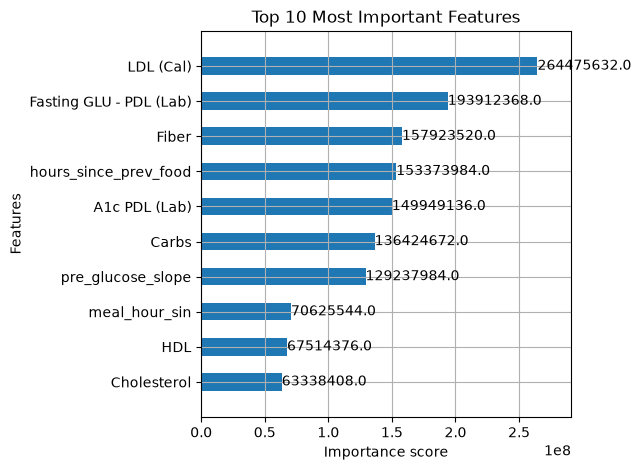

  [M4] done (train 840 meals / 31 participants, validation 215 meals / 9 participants)

M4 pooled out-of-fold results (1s):
   model target       variant     RMSE      MAE     R2  mean_participant_MAE
Baseline      - training_mean 3935.068 2964.807 -0.020              2854.456
   Ridge  y_raw           raw 3343.477 2544.183  0.263              2471.242
 XGBoost  y_raw           raw 3351.741 2614.303  0.260              2528.129

All runs finished in 0.0 min.


In [40]:
oof_tables, param_tables, set_summaries = [], [], []
t_start = time.time()

for set_name, columns in FEATURE_SETS.items():
    data = DATASETS[set_name]
    print(f"\n=== {set_name}: {len(columns)} features, {len(data)} meals, "
          f"{data['subject'].nunique()} participants ===")
    t0 = time.time()
    oof, params = run_cv(set_name, columns, data)
    oof_tables.append(oof)

    summary = summarize(oof)
    set_summaries.append(summary)
    print(f"\n{set_name} pooled out-of-fold results ({time.time() - t0:.0f}s):")
    print(summary[["model", "target", "variant", "RMSE", "MAE", "R2", "mean_participant_MAE" ]].round(3).to_string(index=False))

oof_predictions = pd.concat(oof_tables, ignore_index=True)
metrics = pd.concat(set_summaries, ignore_index=True)
print(f"\nAll runs finished in {(time.time() - t_start) / 60:.1f} min.")

In [41]:
conditions = [
    bio['A1c PDL (Lab)'] >= 6.5,
    bio['A1c PDL (Lab)'] >= 5.7
]
choices = ['diabetes', 'prediabetes']
bio['health_status'] = np.select(conditions, choices, default='healthy')

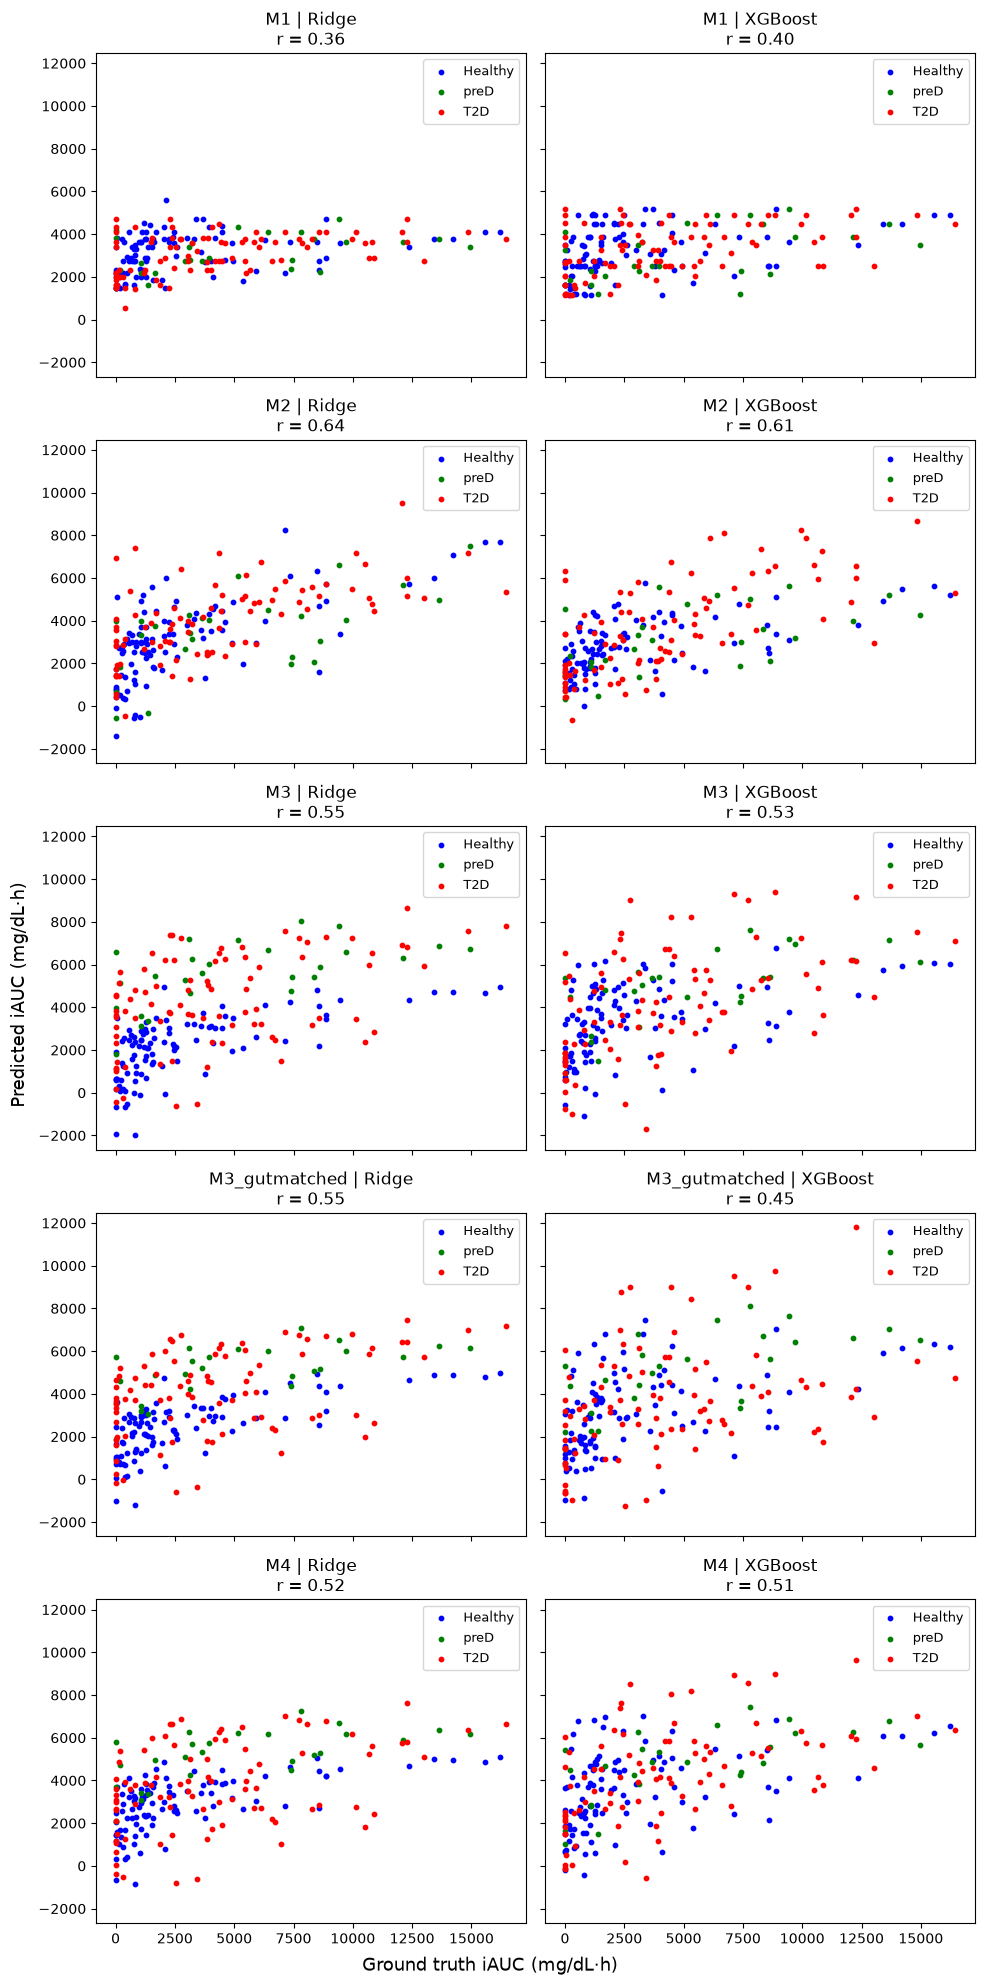

In [42]:
plot_data = oof_predictions.merge(
    bio[["subject", "health_status"]],
    on="subject",
    how="left",
    validate="many_to_one",
)

# Your current models use raw targets.
plot_data = plot_data[
    plot_data["variant"].isin(["raw", "training_mean"])
]

feature_sets = plot_data["feature_set"].drop_duplicates().tolist()
models = plot_data["model"].drop_duplicates().tolist()
models = models[1:]
fig, axes = plt.subplots(
    len(feature_sets), len(models),
    figsize=(5 * len(models), 4 * len(feature_sets)),
    sharex=True, sharey=True, squeeze=False,
)

for row, feature_set in enumerate(feature_sets):
    for col, model in enumerate(models):
        ax = axes[row, col]

        group = plot_data[
            (plot_data["feature_set"] == feature_set)
            & (plot_data["model"] == model)
        ]

        if group.empty:
            ax.set_visible(False)
            continue

        actual = group["y_true"].to_numpy() 
        predicted = group["y_pred"].to_numpy() 

        for status, color, label in [
            ("healthy", "blue", "Healthy"),
            ("prediabetes", "green", "preD"),
            ("diabetes", "red", "T2D"),
        ]:
            index = group["health_status"].eq(status).to_numpy()
            ax.scatter(
                actual[index], predicted[index],
                color=color, s=10, label=label,
            )

        if len(actual) >= 2 and np.ptp(actual) > 0 and np.ptp(predicted) > 0:
            correlation = f"{pearsonr(actual, predicted)[0]:.2f}"
        else:
            correlation = "undefined"

        ax.set_title(f"{feature_set} | {model}\nr = {correlation}")
        ax.legend(fontsize=9)

fig.supxlabel("Ground truth iAUC (mg/dL·h)", fontsize=13)
fig.supylabel("Predicted iAUC (mg/dL·h)", fontsize=13)
plt.tight_layout()
plt.show()

## 8. Results
Metrics are pooled out-of-fold, on the original mg/dL·min scale unless marked `_log`. Lower is better for RMSE, MAE and participant MAE; higher is better for R² and Spearman ρ. `pct_participants_better_than_mean` is the share of participants whose own MAE beats the training-mean baseline. `target` says which outcome the model was trained on (`y_raw`).

In [43]:
SET_ORDER = list(FEATURE_SETS)
metrics["feature_set"] = pd.Categorical(metrics["feature_set"], SET_ORDER, ordered=True)
metrics = metrics.sort_values(["feature_set", "model", "target", "variant"]).reset_index(drop=True)

print("Full results table (every set x model x target x back-transform):")
display(metrics.round(3))

# One row per set x run, using each run's primary back-transform
label_map = {(m, t, v): label for m, t, v, label in PRIMARY_RUNS}
primary = metrics[metrics.apply(lambda r: (r["model"], r["target"], r["variant"]) in label_map, axis=1)].copy()
primary["label"] = primary.apply(lambda r: label_map[(r["model"], r["target"], r["variant"])], axis=1)
baseline_rows = metrics[(metrics["model"] == "Baseline") & (metrics["variant"] == "training_mean")].copy()
baseline_rows["label"] = "Baseline (mean)"
primary = pd.concat([baseline_rows, primary], ignore_index=True)
COLUMN_ORDER = ["Baseline (mean)"] + RUN_LABELS

for column in ["R2", "RMSE", "MAE", "mean_participant_MAE"]:
    print(f"\n{column}  (rows = feature set, columns = model run):")
    print(primary.pivot(index="feature_set", columns="label", values=column)[COLUMN_ORDER]
          .round(3).to_string())

print("\n\n===== SCORES: y_raw =====")
for model in ["Ridge", "XGBoost"]:
    block = metrics[(metrics["model"] == model)
                    & (((metrics["target"] == "y_raw") & (metrics["variant"] == "raw")))]
    print(f"\n{model}:")
    display(block[["feature_set", "target", "variant", "RMSE", "MAE", "R2", "mean_participant_MAE",
                  "negative_predictions"]].round(3))

candidates = metrics[metrics["model"] != "Baseline"]
print("\nBest configuration per feature set (lowest MAE):")
display(candidates.loc[candidates.groupby("feature_set", observed=True)["MAE"].idxmin(),
                       ["feature_set", "model", "target", "variant", "RMSE", "MAE", "R2",
                        "mean_participant_MAE"]].round(3))

Full results table (every set x model x target x back-transform):


,feature_set,model,target,variant,RMSE,MAE,R2,mean_participant_MAE,negative_predictions,pct_participants_better_than_mean
0,M1,Baseline,-,training_mean,3940.900,2958.698,-0.023,2847.182,0,0.000
1,M1,Ridge,y_raw,raw,3723.099,2741.599,0.087,2630.829,0,100.000
2,M1,XGBoost,y_raw,raw,3640.568,2718.076,0.127,2613.353,0,100.000
3,M2,Baseline,-,training_mean,3940.900,2958.698,-0.023,2847.182,0,0.000
4,M2,Ridge,y_raw,raw,3063.113,2282.874,0.382,2210.873,8,88.889
5,M2,XGBoost,y_raw,raw,3206.073,2314.332,0.323,2222.670,1,88.889
6,M3,Baseline,-,training_mean,3940.900,2958.698,-0.023,2847.182,0,0.000
7,M3,Ridge,y_raw,raw,3260.559,2426.835,0.299,2352.710,12,77.778
8,M3,XGBoost,y_raw,raw,3319.175,2608.080,0.274,2538.714,7,66.667
9,M3_gutmatched,Baseline,-,training_mean,3935.068,2964.807,-0.020,2854.456,0,0.000



R2  (rows = feature set, columns = model run):
label          Baseline (mean)  Ridge (raw)  XGBoost (raw)
feature_set                                               
M1                      -0.023        0.087          0.127
M2                      -0.023        0.382          0.323
M3                      -0.023        0.299          0.274
M3_gutmatched           -0.020        0.294          0.184
M4                      -0.020        0.263          0.260

RMSE  (rows = feature set, columns = model run):
label          Baseline (mean)  Ridge (raw)  XGBoost (raw)
feature_set                                               
M1                    3940.900     3723.099       3640.568
M2                    3940.900     3063.113       3206.073
M3                    3940.900     3260.559       3319.175
M3_gutmatched         3935.068     3273.049       3518.097
M4                    3935.068     3343.477       3351.741

MAE  (rows = feature set, columns = model run):
label          Baseline (me

,feature_set,target,variant,RMSE,MAE,R2,mean_participant_MAE,negative_predictions
1,M1,y_raw,raw,3723.099,2741.599,0.087,2630.829,0
4,M2,y_raw,raw,3063.113,2282.874,0.382,2210.873,8
7,M3,y_raw,raw,3260.559,2426.835,0.299,2352.710,12
10,M3_gutmatched,y_raw,raw,3273.049,2448.392,0.294,2379.067,6
13,M4,y_raw,raw,3343.477,2544.183,0.263,2471.242,6



XGBoost:


,feature_set,target,variant,RMSE,MAE,R2,mean_participant_MAE,negative_predictions
2,M1,y_raw,raw,3640.568,2718.076,0.127,2613.353,0
5,M2,y_raw,raw,3206.073,2314.332,0.323,2222.670,1
8,M3,y_raw,raw,3319.175,2608.080,0.274,2538.714,7
11,M3_gutmatched,y_raw,raw,3518.097,2662.747,0.184,2567.242,10
14,M4,y_raw,raw,3351.741,2614.303,0.260,2528.129,5



Best configuration per feature set (lowest MAE):


,feature_set,model,target,variant,RMSE,MAE,R2,mean_participant_MAE
2,M1,XGBoost,y_raw,raw,3640.568,2718.076,0.127,2613.353
4,M2,Ridge,y_raw,raw,3063.113,2282.874,0.382,2210.873
7,M3,Ridge,y_raw,raw,3260.559,2426.835,0.299,2352.710
10,M3_gutmatched,Ridge,y_raw,raw,3273.049,2448.392,0.294,2379.067
13,M4,Ridge,y_raw,raw,3343.477,2544.183,0.263,2471.242


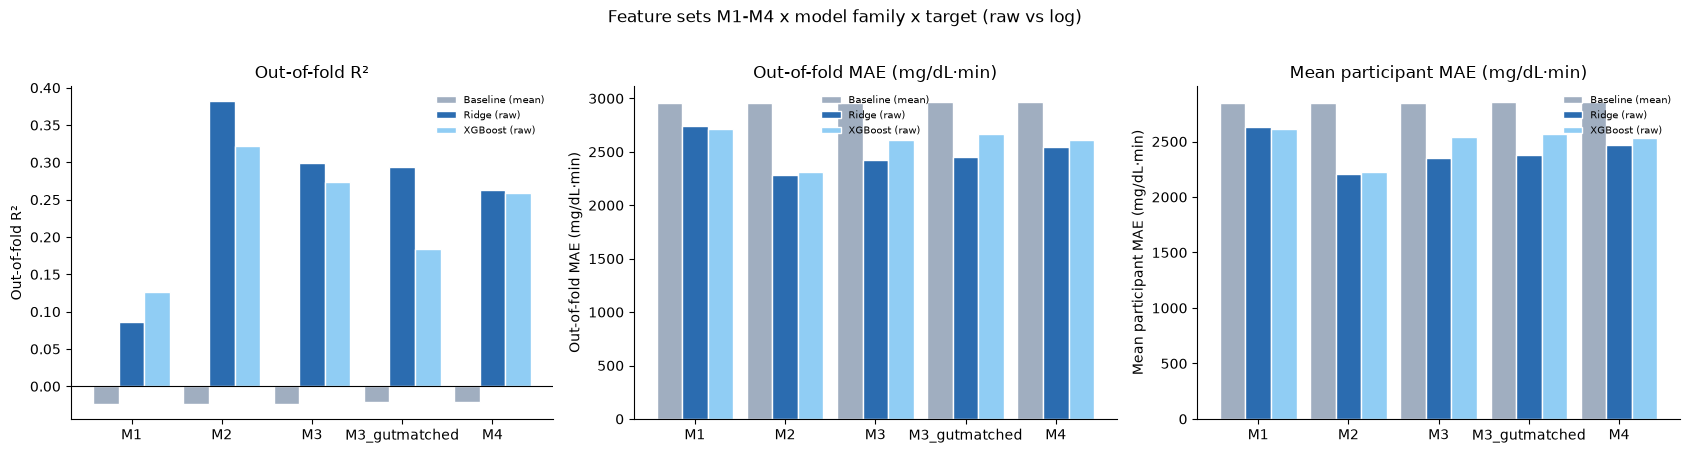

Saved to /Users/pavithraa/Desktop/BME_Data_Science/Project/Glucose-macros-data/cgmacros-code/cgmacros-data/code_rq/repo/results_log_target : ['feature_set_overview.csv', 'meal_iauc_subject_1_20200508_1326.png', 'metrics_all.csv', 'model_dataframe.csv', 'oof_predictions.csv', 'performance_by_feature_set_and_model.png']


In [44]:
colors = dict(zip(COLUMN_ORDER, ["#a0aec0", "#2b6cb0", "#90cdf4", "#2f855a", "#9ae6b4", "#dd6b20"]))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, (column, label) in zip(axes, [("R2", "Out-of-fold R²"), ("MAE", "Out-of-fold MAE (mg/dL·min)"),
                                      ("mean_participant_MAE", "Mean participant MAE (mg/dL·min)")]):
    table = primary.pivot(index="feature_set", columns="label", values=column)[COLUMN_ORDER].loc[SET_ORDER]
    table.plot.bar(ax=ax, color=[colors[c] for c in COLUMN_ORDER], width=0.85, edgecolor="white")
    ax.set(xlabel="", ylabel=label, title=label)
    ax.tick_params(axis="x", rotation=0)
    ax.spines[["top", "right"]].set_visible(False)
    if column == "R2":
        ax.axhline(0, color="black", lw=0.8)
    ax.legend(frameon=False, fontsize=7)
fig.suptitle("Feature sets M1-M4 x model family x target (raw vs log)", y=1.02)
fig.tight_layout()
fig.savefig(OUT_DIR / "performance_by_feature_set_and_model.png", dpi=300, bbox_inches="tight")
plt.show()

metrics.to_csv(OUT_DIR / "metrics_all.csv", index=False)
oof_predictions.to_csv(OUT_DIR / "oof_predictions.csv", index=False)
overview.to_csv(OUT_DIR / "feature_set_overview.csv", index=False)
print("Saved to", OUT_DIR.resolve(), ":", sorted(p.name for p in OUT_DIR.iterdir()))

# RQ2: Principal Component Analysis 
Feature importance analysis

In [45]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

for set_name, columns in FEATURE_SETS.items():
    data = DATASETS[set_name]
    print(f"\n=== {set_name}: {len(columns)} features, {len(data)} meals, "
          f"{data['subject'].nunique()} participants ===")
    
    # Drop rows with missing values in the selected features
    X = data[columns].dropna().to_numpy()
    
    # Standardize the features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Initialize and fit PCA
    pca = PCA(n_components=4)  # You can adjust the number of components as needed
    X_pca = pca.fit_transform(X_scaled)
    
    # Get PCA loadings (eigenvectors)
    pca_loadings = pd.DataFrame(pca.components_.T, index=columns, columns=[f'PC{i+1}' for i in range(pca.n_components_)])
    
    # Sort and display the top 10 loadings for the first principal component
    top_10_loadings = pca_loadings['PC1'].abs().sort_values(ascending=False).head(10)
    
    print(f"\nTop 10 PCA Loadings for {set_name} (PC1):")
    display(top_10_loadings.round(4))




=== M1: 4 features, 1139 meals, 43 participants ===

Top 10 PCA Loadings for M1 (PC1):


Fat        0.5757
Carbs      0.5379
Protein    0.4476
Fiber      0.4229
Name: PC1, dtype: float64


=== M2: 19 features, 1139 meals, 43 participants ===

Top 10 PCA Loadings for M2 (PC1):


meal_breakfast           0.4346
meal_hour_sin            0.4133
hours_since_prev_food    0.4058
pre_activity_z           0.2836
pre_mets_mean            0.2833
pre_actcal_mean          0.2724
Fiber                    0.2605
meal_dinner              0.2270
pre_hr_mean              0.1810
meal_lunch               0.1700
Name: PC1, dtype: float64


=== M3: 29 features, 1139 meals, 43 participants ===

Top 10 PCA Loadings for M3 (PC1):


Fasting GLU - PDL (Lab)    0.3583
VLDL (Cal)                 0.3447
Triglycerides              0.3442
A1c PDL (Lab)              0.3180
HDL                        0.3173
pre_glucose_mean           0.3002
pre_glucose_last           0.2831
Insulin                    0.2328
BMI                        0.2289
pre_hr_mean                0.1530
Name: PC1, dtype: float64


=== M3_gutmatched: 29 features, 1055 meals, 40 participants ===

Top 10 PCA Loadings for M3_gutmatched (PC1):


HDL                        0.3400
Fasting GLU - PDL (Lab)    0.3333
VLDL (Cal)                 0.3118
Triglycerides              0.3112
A1c PDL (Lab)              0.2923
pre_glucose_mean           0.2919
pre_glucose_last           0.2810
pre_hr_mean                0.2502
Insulin                    0.2338
BMI                        0.2027
Name: PC1, dtype: float64


=== M4: 51 features, 1055 meals, 40 participants ===

Top 10 PCA Loadings for M4 (PC1):


Microbiome-Induced Stress         0.2928
Butyrate Production Pathways      0.2775
Putrescine Production Pathways    0.2765
Bile Acid Metabolism Pathways     0.2553
Protein Fermentation              0.2488
Flagellar Assembly Pathways       0.2480
Gut Microbiome Health             0.2428
Inflammatory Activity             0.2366
Active Microbial Diversity        0.2317
Digestive Efficiency              0.2156
Name: PC1, dtype: float64

In [46]:
# Only health columns
X = model_df[health_columns].dropna().to_numpy()  
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pca = PCA(n_components=4)
X_pca = pca.fit_transform(X_scaled)
pca_loadings = pd.Series(pca.components_[0], index=model_df[health_columns].columns)
top_10_loadings = pca_loadings.abs().sort_values(ascending=False).head(10)

print("Original shape:", X_scaled.shape)
print("Reduced shape:", X_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance retained:", sum(pca.explained_variance_ratio_))
print("\nPCA Loadings (Eigenvectors * sqrt(explained_variance)):")
display(top_10_loadings.round(4))

Original shape: (1108, 10)
Reduced shape: (1108, 4)
Explained variance ratio: [0.37453807 0.19715891 0.17578929 0.10023577]
Total variance retained: 0.8477220369898034

PCA Loadings (Eigenvectors * sqrt(explained_variance)):


Triglycerides              0.4354
VLDL (Cal)                 0.4348
HDL                        0.3316
Fasting GLU - PDL (Lab)    0.3307
Insulin                    0.3183
A1c PDL (Lab)              0.3112
BMI                        0.2908
LDL (Cal)                  0.2334
Cholesterol                0.2284
Age                        0.1129
dtype: float64

## Few Extensions

## Leave-one-participant-out (LOPO) CV: M1–M4 => Ridge/XGBoost

This evaluates every eligible participant as a held-out test participant exactly once. For each held-out participant and feature set, hyperparameters are chosen by grouped CV on the remaining participants, so meals from a participant never cross the train/validation boundary. Imputation/scaling are fit inside each training fold. XGBoost uses its native missing-value handling.

M1–M3 use the full cohort. M4 uses gut-profile participants only. Thus M4 has a smaller cohort and should be compared with M3 on the same gut-matched participants when judging the incremental value of gut features. 

In [47]:
# LOPO CV settings. For final analysis, keep the inner folds as high as practical.
LOPO_INNER_FOLDS = min(5, model_df["subject"].nunique() - 1)
LOPO_N_JOBS = -1
LOPO_XGB_GRID = {
    "max_depth": [1, 2, 3],
    "n_estimators": [50, 80, 100],
    "learning_rate": [0.1, 0.2, 0.3],
}

# Include a matched-cohort M3 comparator for a fair comparison against M4.
LOPO_SETS = {
    "M1": (M1, full_data),
    "M2": (M2, full_data),
    "M3": (M3, full_data),
    "M3_gutmatched": (M3, matched_data),
    "M4": (M4, matched_data),
}

def _make_inner_splits(groups):
    n_groups = pd.Series(groups).nunique()
    n_splits = min(LOPO_INNER_FOLDS, n_groups)
    return list(GroupKFold(n_splits=n_splits).split(np.zeros(len(groups)), groups=groups))

def run_lopo_set(set_name, columns, data):
    pred_rows, param_rows = [], []
    participants = sorted(data["subject"].unique())
    for fold, held_out in enumerate(participants, start=1):
        train = data.loc[data["subject"] != held_out]
        test = data.loc[data["subject"] == held_out]
        assert not set(train.subject).intersection(test.subject)
        inner_splits = _make_inner_splits(train["subject"].to_numpy())
        for model_name in ["Ridge", "XGBoost"]:
            if model_name == "Ridge":
                estimator = clone(food_pipeline)
                grid = ridge_grid
            else:
                estimator = xgb.XGBRegressor(
                    reg_alpha=1, reg_lambda=0, random_state=SEED, n_jobs=1,
                    objective="reg:squarederror", eval_metric="rmse",
                )
                grid = LOPO_XGB_GRID
            search = GridSearchCV(
                estimator=estimator, param_grid=grid, scoring="neg_mean_squared_error",
                cv=inner_splits, n_jobs=LOPO_N_JOBS, refit=True, error_score="raise",
            )
            search.fit(train[columns], train["y_raw"])
            yhat = np.asarray(search.predict(test[columns])).reshape(-1)
            pred_rows.append(pd.DataFrame({
                "feature_set": set_name, "model": model_name, "fold": fold,
                "subject": test["subject"].to_numpy(),
                "event_timestamp": test["event_timestamp"].to_numpy(),
                "meal_type": test["meal_type"].to_numpy(),
                "y_true": test["y_raw"].to_numpy(), "y_pred": yhat,
            }))
            param_rows.append({
                "feature_set": set_name, "model": model_name, "fold": fold,
                "held_out_subject": held_out, "inner_cv_score_neg_mse": search.best_score_,
                **best_params_dict(search),
            })
        print(f"{set_name}: participant {held_out} ({fold}/{len(participants)}) complete")
    return pd.concat(pred_rows, ignore_index=True), pd.DataFrame(param_rows)

def lopo_metrics(predictions):
    y, p = predictions["y_true"].to_numpy(), predictions["y_pred"].to_numpy()
    by_subject = (predictions.assign(abs_error=np.abs(y-p))
                  .groupby("subject")["abs_error"].mean())
    return pd.Series({
        "participants": predictions["subject"].nunique(),
        "meals": len(predictions),
        "RMSE": np.sqrt(mean_squared_error(y, p)),
        "MAE": mean_absolute_error(y, p),
        "R2": r2_score(y, p),
        "mean_participant_MAE": by_subject.mean(),
        "negative_predictions": int((p < 0).sum()),
    })

lopo_prediction_blocks, lopo_parameter_blocks = [], []
for _set_name, (_columns, _data) in LOPO_SETS.items():
    print(f"\n=== LOPO {_set_name}: {_data.subject.nunique()} participants, {len(_data)} meals ===")
    _pred, _params = run_lopo_set(_set_name, _columns, _data)
    lopo_prediction_blocks.append(_pred)
    lopo_parameter_blocks.append(_params)

lopo_predictions = pd.concat(lopo_prediction_blocks, ignore_index=True)
lopo_parameters = pd.concat(lopo_parameter_blocks, ignore_index=True)
lopo_summary = (lopo_predictions.groupby(["feature_set", "model"], sort=False)
                .apply(lopo_metrics, include_groups=False).reset_index())
print("\nLOPO results (raw iAUC, mg/dL·min):")
display(lopo_summary.round(3))


=== LOPO M1: 43 participants, 1139 meals ===
M1: participant 1 (1/43) complete
M1: participant 2 (2/43) complete
M1: participant 3 (3/43) complete
M1: participant 4 (4/43) complete
M1: participant 5 (5/43) complete
M1: participant 6 (6/43) complete
M1: participant 8 (7/43) complete
M1: participant 9 (8/43) complete
M1: participant 10 (9/43) complete
M1: participant 11 (10/43) complete
M1: participant 12 (11/43) complete
M1: participant 13 (12/43) complete
M1: participant 14 (13/43) complete
M1: participant 15 (14/43) complete
M1: participant 16 (15/43) complete
M1: participant 17 (16/43) complete
M1: participant 19 (17/43) complete
M1: participant 20 (18/43) complete
M1: participant 21 (19/43) complete
M1: participant 22 (20/43) complete
M1: participant 23 (21/43) complete
M1: participant 26 (22/43) complete
M1: participant 27 (23/43) complete
M1: participant 28 (24/43) complete
M1: participant 29 (25/43) complete
M1: participant 30 (26/43) complete
M1: participant 31 (27/43) complete

,feature_set,model,participants,meals,RMSE,MAE,R2,mean_participant_MAE,negative_predictions
0,M1,Ridge,43.0,1139.0,3001.637,2297.535,0.089,2272.682,0.0
1,M1,XGBoost,43.0,1139.0,2920.690,2214.782,0.138,2196.044,2.0
2,M2,Ridge,43.0,1139.0,2697.486,2041.629,0.264,2011.012,30.0
3,M2,XGBoost,43.0,1139.0,2668.319,2024.488,0.280,1983.413,6.0
4,M3,Ridge,43.0,1139.0,2983.937,2110.109,0.100,2062.478,52.0
5,M3,XGBoost,43.0,1139.0,2554.575,1873.626,0.340,1835.184,12.0
6,M3_gutmatched,Ridge,40.0,1055.0,2826.305,2114.478,0.231,2077.094,48.0
7,M3_gutmatched,XGBoost,40.0,1055.0,2655.381,1968.006,0.321,1926.647,24.0
8,M4,Ridge,40.0,1055.0,2935.331,2232.741,0.171,2202.410,9.0
9,M4,XGBoost,40.0,1055.0,2723.278,2001.924,0.286,1958.269,18.0


## Mixed-effects model: carbohydrate–iAUC association by health group

The analysis below fits one linear mixed model to meal-level data: `iAUC ~ carbohydrate × health group + participant random intercept`. It uses a random intercept because each participant contributes multiple meals. Carbohydrates and iAUC are scaled for numerical stability; coefficients are therefore change in iAUC standard deviations per one carbohydrate standard deviation. The interaction tests whether the carbohydrate slope differs by group.

Health groups are defined using HbA1c: healthy <5.7%, prediabetes 5.7–<6.5%, diabetes ≥6.5%. Rows without HbA1c or carbohydrate/iAUC are excluded from this analysis only. Interpret group-specific slopes cautiously because the effective independent sample is the number of participants, not the number of meals.

In [48]:
# ------------------------------------------------------------
# 1. Prepare meal data and HbA1c-defined health groups
# ------------------------------------------------------------

health = bio[["subject", "A1c PDL (Lab)"]].copy()
a1c = pd.to_numeric(health["A1c PDL (Lab)"], errors="coerce")

health["health_status"] = np.select(
    [a1c >= 6.5, a1c >= 5.7],
    ["diabetes", "prediabetes"],
    default="healthy",
)
health.loc[a1c.isna(), "health_status"] = pd.NA

feature_axis = "Fiber" # Carbs , Protein ,	Fat ,	Fiber
mixed_df = model_df[["subject", feature_axis, "y_raw"]].merge(
    health[["subject", "health_status"]],
    on="subject",
    how="left",
    validate="many_to_one",
)

for column in [feature_axis, "y_raw"]:
    mixed_df[column] = pd.to_numeric(
        mixed_df[column], errors="coerce"
    )

mixed_df = (
    mixed_df.replace([np.inf, -np.inf], np.nan)
    .dropna(subset=["subject", "health_status", feature_axis, "y_raw"])
    .copy()
)

groups = ["healthy", "prediabetes", "diabetes"]

mixed_df["health_status"] = pd.Categorical(
    mixed_df["health_status"],
    categories=groups,
)

group_summary = (
    mixed_df.groupby("health_status", observed=False)
    .agg(
        participants=("subject", "nunique"),
        meals=("subject", "size"),
        mean_carbs_g=(feature_axis, "mean"),
        mean_iauc=("y_raw", "mean"),
    )
)

print("Rows by health group:")
display(group_summary.round(2))

# Scale both variables to help the optimizer.
carbs_mean = mixed_df[feature_axis].mean()
carbs_sd = mixed_df[feature_axis].std(ddof=0)
iauc_mean = mixed_df["y_raw"].mean()
iauc_sd = mixed_df["y_raw"].std(ddof=0)

mixed_df["carbs_z"] = (
    mixed_df[feature_axis] - carbs_mean
) / carbs_sd

mixed_df["iauc_z"] = (
    mixed_df["y_raw"] - iauc_mean
) / iauc_sd


# ------------------------------------------------------------
# 2. Fit participant random-intercept models
# ------------------------------------------------------------
group_term = "C(health_status, Treatment(reference='healthy'))"

formula_full = f"iauc_z ~ carbs_z * {group_term}"
formula_common = f"iauc_z ~ carbs_z + {group_term}"


def fit_mixed_model(formula, reml, name):
    """Try another optimizer if fitting fails or does not converge."""
    method = "lbfgs"
    result = smf.mixedlm(
        formula,
        data=mixed_df,
        groups=mixed_df["subject"],
        re_formula="1",  # participant random intercept
    ).fit(
        reml=reml,
        method=method,
        maxiter=2000,
        disp=False,
    )

    fixed_cov = result.cov_params().loc[
        result.fe_params.index,
        result.fe_params.index,
    ].to_numpy()

    valid = (
        result.converged
        and np.isfinite(result.llf)
        and np.isfinite(result.fe_params.to_numpy()).all()
        and np.isfinite(fixed_cov).all()
        and (np.diag(fixed_cov) > 0).all()
    )

    if valid:
        print(f"{name}: converged using {method}")
        return result

    print(f"{name}: {method} did not produce a usable fit.")


# ML fits are needed to compare different fixed-effect formulas.
fit_full_ml = fit_mixed_model(
    formula_full, reml=False, name="Full model: ML"
)
fit_common_ml = fit_mixed_model(
    formula_common, reml=False, name="Common slope: ML"
)

# REML fit is used for the reported coefficients and slopes.
fit_full = fit_mixed_model(
    formula_full, reml=True, name="Full model: REML"
)

diagnostics = pd.DataFrame([
    {
        "model": name,
        "converged": fit.converged,
        "participant_variance": float(fit.cov_re.iloc[0, 0]),
        "residual_variance": fit.scale,
        "log_likelihood": fit.llf,
    }
    for name, fit in [
        ("Full ML", fit_full_ml),
        ("Common-slope ML", fit_common_ml),
        ("Full REML", fit_full),
    ]
])

print("\nFit diagnostics:")
display(diagnostics.round(5))


# ------------------------------------------------------------
# 3. Test whether carbohydrate slopes differ between groups
# ------------------------------------------------------------
lr_stat = 2 * (fit_full_ml.llf - fit_common_ml.llf)
lr_df = len(fit_full_ml.fe_params) - len(fit_common_ml.fe_params)


lr_stat = max(0.0, lr_stat)
interaction_p = chi2.sf(lr_stat, lr_df)

print(
    f"\nOverall carbohydrate × health-group interaction:\n"
    f"LR = {lr_stat:.3f}, df = {lr_df}, p = {interaction_p:.5f}"
)

print("\nREML model summary:")
print(fit_full.summary())


# ------------------------------------------------------------
# 4. Correct group-specific slopes and confidence intervals
# ------------------------------------------------------------
fe = fit_full.fe_params
cov = fit_full.cov_params().loc[fe.index, fe.index]

# Convert standardized slope to raw iAUC change per 10 g carbs.
conversion = 10 * iauc_sd / carbs_sd
slope_rows = []

for group in groups:
    contrast = pd.Series(0.0, index=fe.index)
    contrast["carbs_z"] = 1.0

    if group != "healthy":
        # Exact coefficient name prevents diabetes/prediabetes confusion.
        interaction_name = f"carbs_z:{group_term}[T.{group}]"

        if interaction_name not in fe.index:
            raise KeyError(f"Missing coefficient: {interaction_name}")

        contrast[interaction_name] = 1.0

    estimate = float(contrast @ fe)
    variance = float(contrast @ cov @ contrast)

    if not np.isfinite(variance) or variance <= 0:
        raise RuntimeError(f"Invalid slope variance for {group}.")

    se = np.sqrt(variance)
    low = estimate - norm.ppf(0.975) * se
    high = estimate + norm.ppf(0.975) * se
    p_value = 2 * norm.sf(abs(estimate / se))

    slope_rows.append({
        "health_status": group,
        "standardized_slope": estimate,
        "slope_iAUC_per_10g_carbs": estimate * conversion,
        "CI95_low_per_10g": low * conversion,
        "CI95_high_per_10g": high * conversion,
        "p_value_Wald": p_value,
        "participants": int(group_summary.loc[group, "participants"]),
        "meals": int(group_summary.loc[group, "meals"]),
    })

carb_group_slopes = pd.DataFrame(slope_rows)

print("\nGroup-specific carbohydrate slopes:")
# Scientific notation avoids displaying small p-values as zero.
display(
    carb_group_slopes.style.format({
        "standardized_slope": "{:.4f}",
        "slope_iAUC_per_10g_carbs": "{:.2f}",
        "CI95_low_per_10g": "{:.2f}",
        "CI95_high_per_10g": "{:.2f}",
        "p_value_Wald": "{:.3g}",
    })
)

carb_group_slopes.to_csv(
    OUT_DIR / "mixed_model_carbohydrate_slopes.csv",
    index=False,
)
diagnostics.to_csv(
    OUT_DIR / "mixed_model_diagnostics.csv",
    index=False,
)

Rows by health group:


,participants,meals,mean_carbs_g,mean_iauc
health_status,,,,
healthy,14,332,4.28,2215.71
prediabetes,15,424,4.89,3185.08
diabetes,14,367,4.79,4419.67


Full model: ML: converged using lbfgs
Common slope: ML: converged using lbfgs
Full model: REML: converged using lbfgs

Fit diagnostics:


/opt/anaconda3/envs/bme_data_science/lib/python3.14/site-packages/statsmodels/base/model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.score(params, *args) / nobs
/opt/anaconda3/envs/bme_data_science/lib/python3.14/site-packages/statsmodels/base/model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.score(params, *args) / nobs
/opt/anaconda3/envs/bme_data_science/lib/python3.14/site-packages/statsmodels/base/model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.score(params, *args) / nobs


,model,converged,participant_variance,residual_variance,log_likelihood
0,Full ML,True,0.16694,0.68630,-1424.74023
1,Common-slope ML,True,0.16571,0.72654,-1455.54472
2,Full REML,True,0.18132,0.68823,-1434.99241



Overall carbohydrate × health-group interaction:
LR = 61.609, df = 2, p = 0.00000

REML model summary:
                                      Mixed Linear Model Regression Results
Model:                                MixedLM                    Dependent Variable:                    iauc_z    
No. Observations:                     1123                       Method:                                REML      
No. Groups:                           43                         Scale:                                 0.6882    
Min. group size:                      17                         Log-Likelihood:                        -1434.9924
Max. group size:                      38                         Converged:                             Yes       
Mean group size:                      26.1                                                                        
------------------------------------------------------------------------------------------------------------------
               

,health_status,standardized_slope,slope_iAUC_per_10g_carbs,CI95_low_per_10g,CI95_high_per_10g,p_value_Wald,participants,meals
0,healthy,-0.0807,-496.55,-1098.35,105.24,0.106,14,332
1,prediabetes,-0.0203,-124.74,-589.51,340.03,0.599,15,424
2,diabetes,-0.4692,-2886.90,-3424.58,-2349.22,6.74e-26,14,367


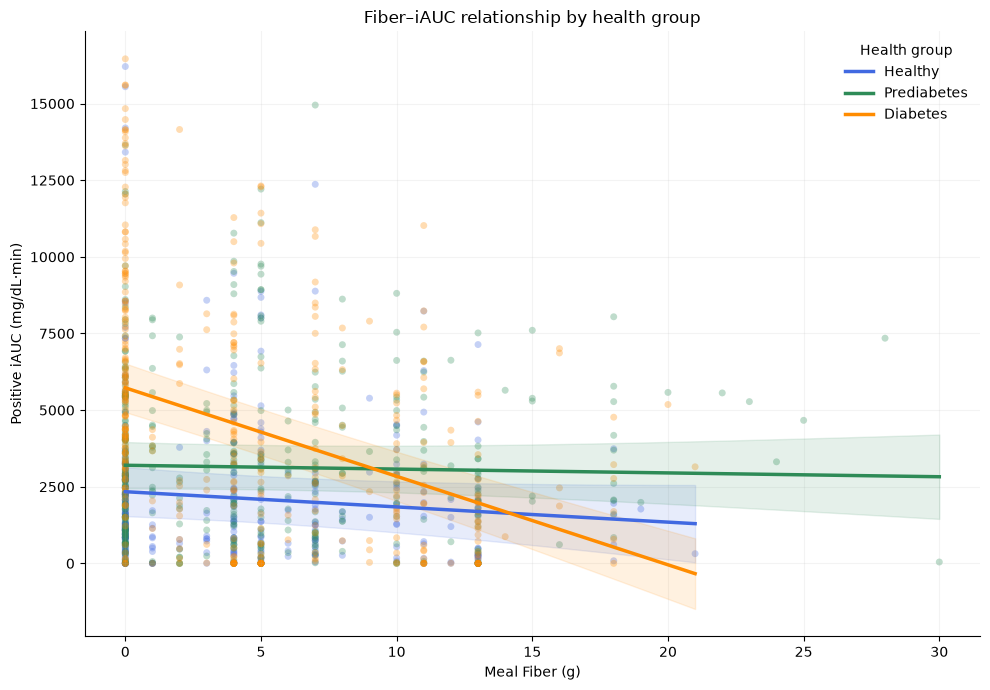

In [49]:
colors = {
    "healthy": "royalblue",
    "prediabetes": "seagreen",
    "diabetes": "darkorange",
}
labels = {
    "healthy": "Healthy",
    "prediabetes": "Prediabetes",
    "diabetes": "Diabetes",
}

beta = fit_full.fe_params
cov = fit_full.cov_params().loc[beta.index, beta.index].to_numpy()

fig, ax = plt.subplots(figsize=(10, 7))

for group, color in colors.items():
    data = mixed_df.loc[mixed_df["health_status"] == group]

    # Actual meals.
    ax.scatter(
        data[feature_axis], data["y_raw"],
        color=color, alpha=0.3, s=25,
        edgecolors="none", zorder=1,
    )

    # Predict across this group's observed carbohydrate range.
    carbs = np.linspace(data[feature_axis].min(), data[feature_axis].max(), 200)
    carbs_z = (carbs - carbs_mean) / carbs_sd

    X = pd.DataFrame(0.0, index=range(len(carbs)), columns=beta.index)
    X["Intercept"] = 1.0
    X["carbs_z"] = carbs_z

    if group != "healthy":
        term = (
            f"C(health_status, Treatment(reference='healthy'))[T.{group}]"
        )
        X[term] = 1.0
        X[f"carbs_z:{term}"] = carbs_z

    X = X.loc[:, beta.index].to_numpy()

    predicted_z = X @ beta.to_numpy()
    se_z = np.sqrt(
        np.maximum(np.einsum("ij,jk,ik->i", X, cov, X), 0)
    )

    predicted = iauc_mean + iauc_sd * predicted_z
    lower = iauc_mean + iauc_sd * (predicted_z - 1.96 * se_z)
    upper = iauc_mean + iauc_sd * (predicted_z + 1.96 * se_z)

    ax.plot(
        carbs, predicted,
        color=color, linewidth=2.5,
        label=labels[group], zorder=3,
    )
    ax.fill_between(
        carbs, lower, upper,
        color=color, alpha=0.12, zorder=2,
    )

ax.set(
    xlabel=f"Meal {feature_axis} (g)",
    ylabel="Positive iAUC (mg/dL·min)",
    title=f"{feature_axis}–iAUC relationship by health group",
)
ax.legend(title="Health group", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.15)

fig.tight_layout()
fig.savefig(
    OUT_DIR / f"{feature_axis.lower()}_iauc_overlay.png",
    dpi=300, bbox_inches="tight",
)
plt.show()